# SBP 1D analysis

Raw spider data restricted to 20–22 GHz before preprocessing; our transverse integrals feed the existing 1D analysis pipeline with four geometry cases. Plots below use the new 100-draw Monte Carlo results. [Details](README.md#1d-measurement-analysis).

### Plot labels and exports

Edit text keywords in each plot cell; rerun to update its PNG/PDF exports under `plots/1d/`. Templates retain plotted values.

In [1]:
from functools import partial
from pathlib import Path
from src import pipeline_plots as plots

plots.configure_style()
RUN_DIR = Path("data/spider_bead_pull_runs/run_20261025_141003")
FREQUENCY_RANGE_GHZ = (20.0, 22.0)
FREQUENCY_GHZ = 20.825
GEOMETRY = "both"  # fixed, gaps, positions, both
ZOOM_GHZ = (20.6, 21.05)
FIT_3D_PATH = None  # 3D results are shown in sbp_3d_analysis.ipynb
FULL_BEAD_FILE = Path("data/full_bead_pull/result_bf_21_0.jld2")
COMPARISON_GHZ = 21.0
PREVIOUS_1D_DIR = Path("data/outputs/run_20261025_141003/history/nominal_gap_8p803mm")
PLOT_ROOT = Path("plots")

### Recompute (optional)

Requires Julia and `julia/analysis_1d`. When ready, set `RUN_ANALYSIS=True` to rebuild our transverse integrals and run the existing 1D pipeline with each geometry case.

In [2]:
from src.sbp_analysis import analyze_run
from src.fit_1D import fit_all_geometries
import numpy as np

RUN_ANALYSIS = False
N_MC = 100
RELATIVE_ET_ERROR = 0.05  # Assumed input error used by the existing 5_ notebook.
RANDOM_SEED = 20261025
if RUN_ANALYSIS:
    fields_file = analyze_run(RUN_DIR)
    with np.load(fields_file) as measured:
        fits = fit_all_geometries(
            measured["frequencies_Hz"], measured["z_from_mirror_m"], measured["ET"],
            n_mc=N_MC, relative_error=RELATIVE_ET_ERROR, seed=RANDOM_SEED,
        )
    for geometry, result in fits.items():
        result.save(fields_file.with_name(f"integrated_fields_fit_1D_{geometry}.npz"))

In [3]:
data = plots.load_pipeline(
    RUN_DIR, fit_3d_path=FIT_3D_PATH, frequency_range_GHz=FREQUENCY_RANGE_GHZ,
)
FIGURE_DIR = PLOT_ROOT / "1d"

In [4]:
plots.summary(data, compact=True)

**Run:** `run_20261025_141003` · **S22** · 401 frequencies, 20–22 GHz.  
**Saved 1D cases:** both, fixed, gaps, positions.  
**Outputs:** `data/outputs/run_20261025_141003`

,z from mirror [mm],Raw positions,Line length [cm],Beam centre from start [cm],Integration radius [cm]
Sub-thread,,,,,
0,32.0110,83,40.8534,27.0220,11.3314
1,23.0835,82,40.4969,21.6782,16.3187
2,13.2295,83,40.8534,19.6544,17.1544
3,3.9015,82,40.4969,23.7467,14.2502


## 1. Setup

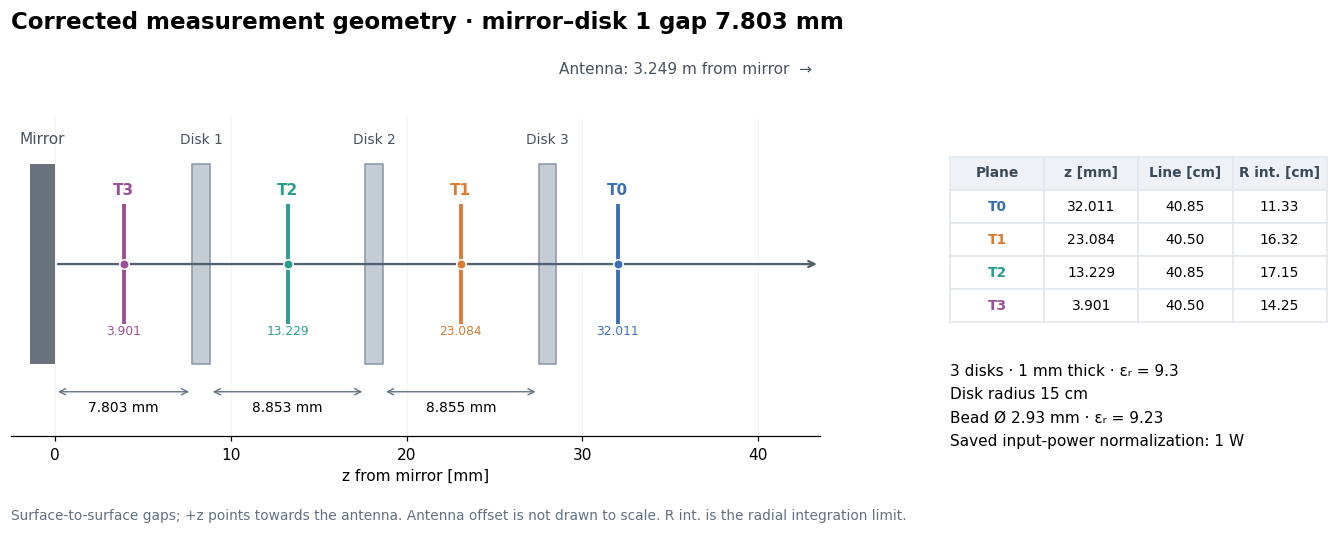

In [5]:
plots.present(
    plots.plot_setup(
        data,
        title="Corrected measurement geometry · mirror–disk 1 gap 7.803 mm",
        x_label="z from mirror [mm]",
        mirror_label="Mirror",
        disk_label_template="Disk {disk_index}",
        thread_label_template="T{thread_index}",
        thread_position_template="{z_mm:.3f}",
        gap_width_template="{gap_mm:.3f} mm",
        antenna_label_template="Antenna: {antenna_distance_m:.3f} m from mirror  →",
        antenna_unknown_label="Antenna lies towards +z  →",
        table_headers=("Plane", "z [mm]", "Line [cm]", "R int. [cm]"),
        table_thread_template="T{thread_index}",
        table_position_template="{z_mm:.3f}",
        table_length_template="{length_cm:.2f}",
        table_radius_template="{radius_cm:.2f}",
        missing_value_label="—",
        properties_template="{disk_count} disks · {disk_thickness_mm:g} mm thick · εᵣ = {disk_eps_r:g}\nDisk radius {disk_radius_cm:g} cm\nBead Ø {bead_diameter_mm:g} mm · εᵣ = {bead_eps_r:g}\nSaved input-power normalization: {input_power_W:g} W",
        footnote="Surface-to-surface gaps; +z points towards the antenna. Antenna offset is not drawn to scale. R int. is the radial integration limit.",
    ),
    '01_setup', FIGURE_DIR / 'measurement/setup',
)

## 2. Raw measurement

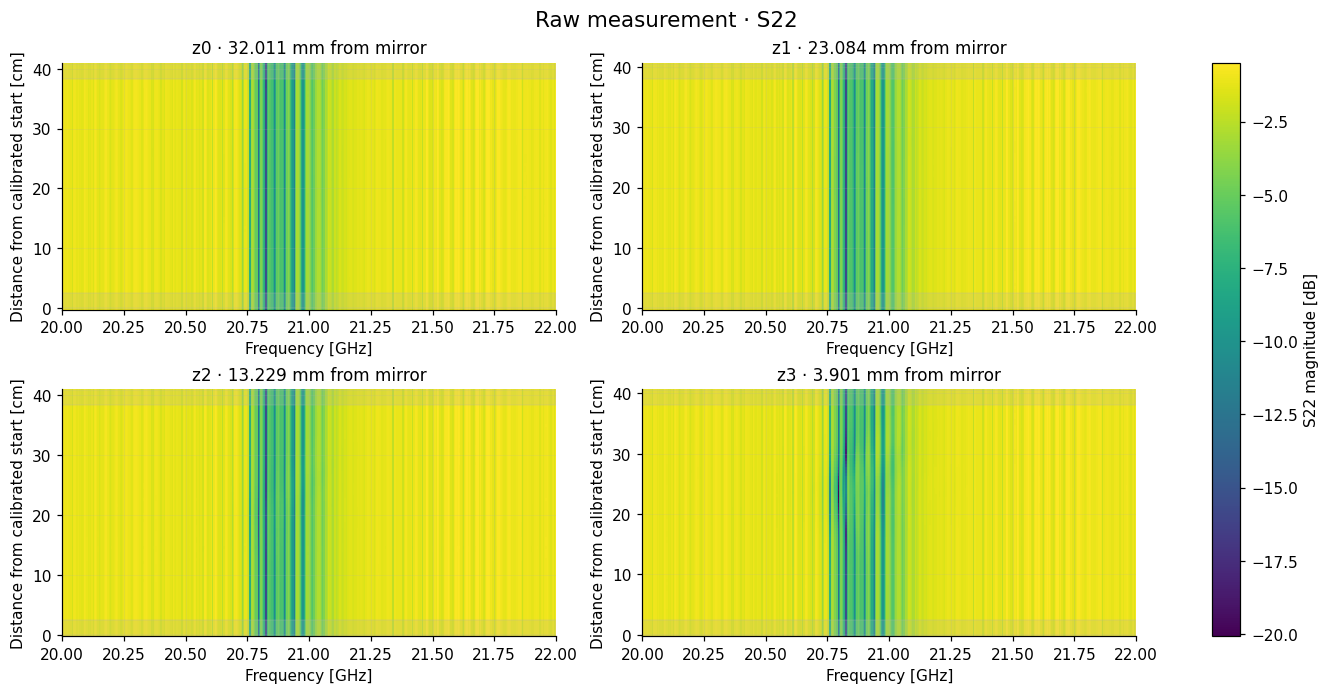

In [6]:
plots.present(
    plots.plot_measurement_map(
        data,
        title="Raw measurement · {s_parameter}",
        panel_title_template="{thread_name} · {z_mm:.3f} mm from mirror",
        x_label="Frequency [GHz]",
        y_label="Distance from calibrated start [cm]",
        colorbar_label="{s_parameter} magnitude [dB]",
    ),
    '02_raw_measurement_map', FIGURE_DIR / 'measurement/raw',
)

## 3. Complex raw traces

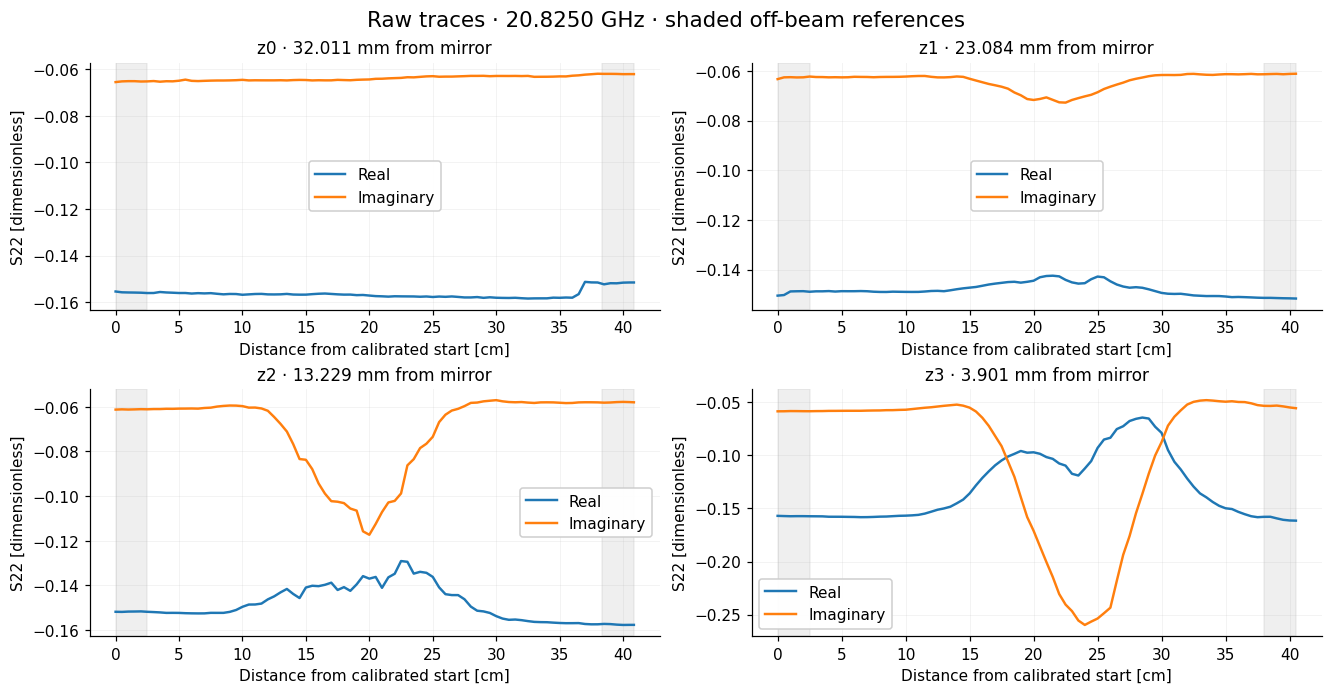

In [7]:
plots.present(
    plots.plot_raw_traces(
        data, FREQUENCY_GHZ,
        title="Raw traces · {frequency_GHz:.4f} GHz · shaded off-beam references",
        panel_title_template="{thread_name} · {z_mm:.3f} mm from mirror",
        x_label="Distance from calibrated start [cm]",
        y_label="{s_parameter} [dimensionless]",
        real_label="Real",
        imaginary_label="Imaginary",
    ),
    '03_raw_traces', FIGURE_DIR / 'measurement/raw',
)

## 4. Reference subtraction

Complex affine background estimated from the line edges.

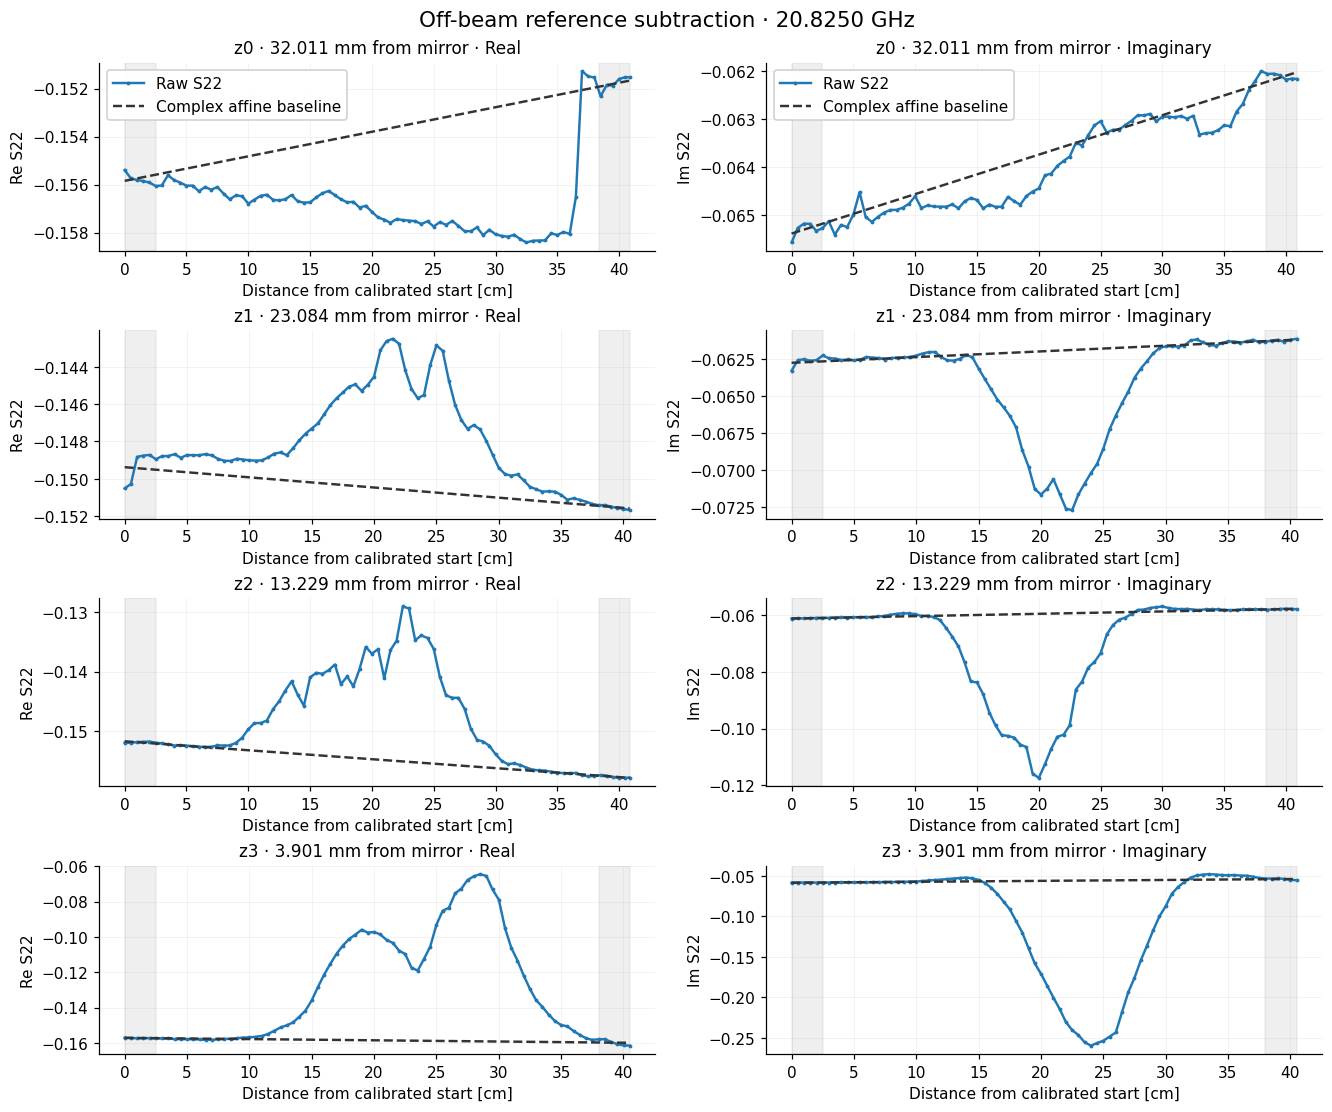

In [8]:
reference_subtraction_plot = partial(
    plots.plot_reference_subtraction,
    title="Off-beam reference subtraction · {frequency_GHz:.4f} GHz",
    panel_title_template="{thread_name} · {z_mm:.3f} mm from mirror · {component}",
    x_label="Distance from calibrated start [cm]",
    real_y_label="Re {s_parameter}",
    imaginary_y_label="Im {s_parameter}",
    real_component_label="Real",
    imaginary_component_label="Imaginary",
    measured_label="Raw {s_parameter}",
    baseline_label="Complex affine baseline",
)
plots.present(reference_subtraction_plot(data, FREQUENCY_GHZ), '04_reference_subtraction', FIGURE_DIR / 'measurement/transverse')

## 5. Beam centre

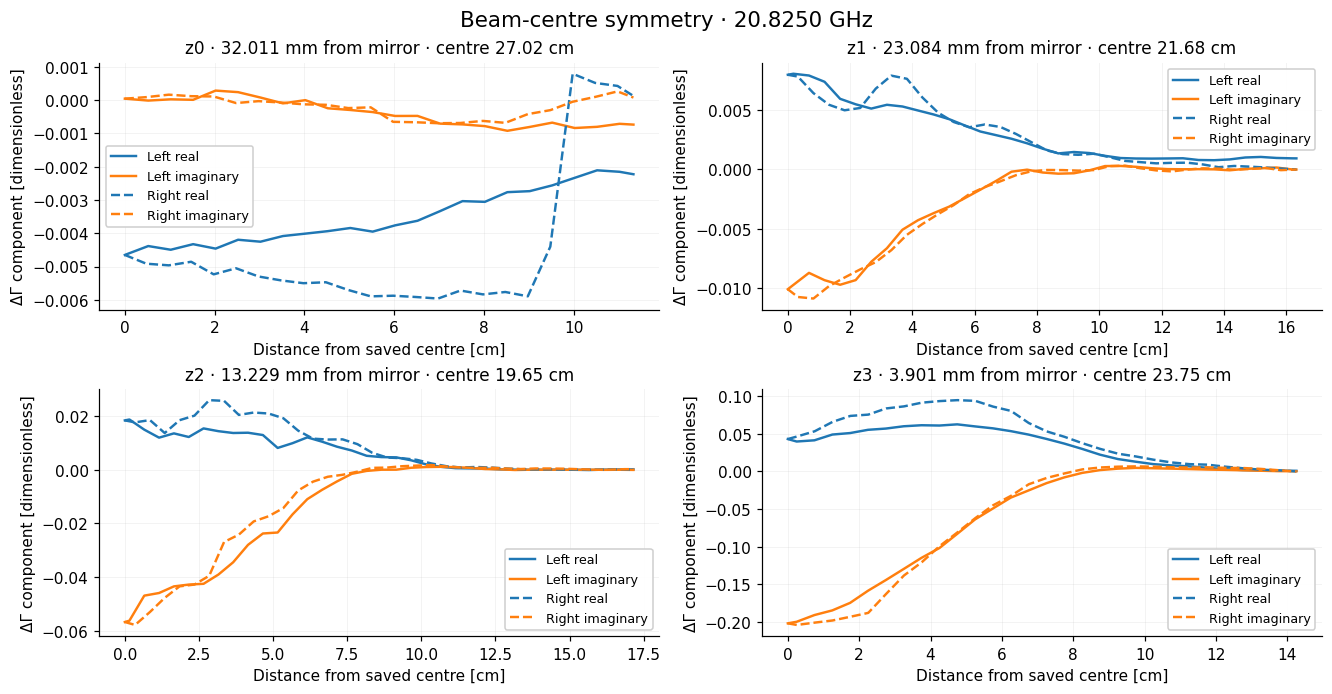

In [9]:
beam_center_plot = partial(
    plots.plot_beam_center,
    title="Beam-centre symmetry · {frequency_GHz:.4f} GHz",
    panel_title_template="{thread_name} · {z_mm:.3f} mm from mirror · centre {center_cm:.2f} cm",
    x_label="Distance from saved centre [cm]",
    y_label="ΔΓ component [dimensionless]",
    left_real_label="Left real",
    left_imaginary_label="Left imaginary",
    right_real_label="Right real",
    right_imaginary_label="Right imaginary",
)
plots.present(beam_center_plot(data, FREQUENCY_GHZ), '05_beam_centre', FIGURE_DIR / 'measurement/transverse')

## 6. Radial field

Finite-bead field estimate from the folded complex reflection change.

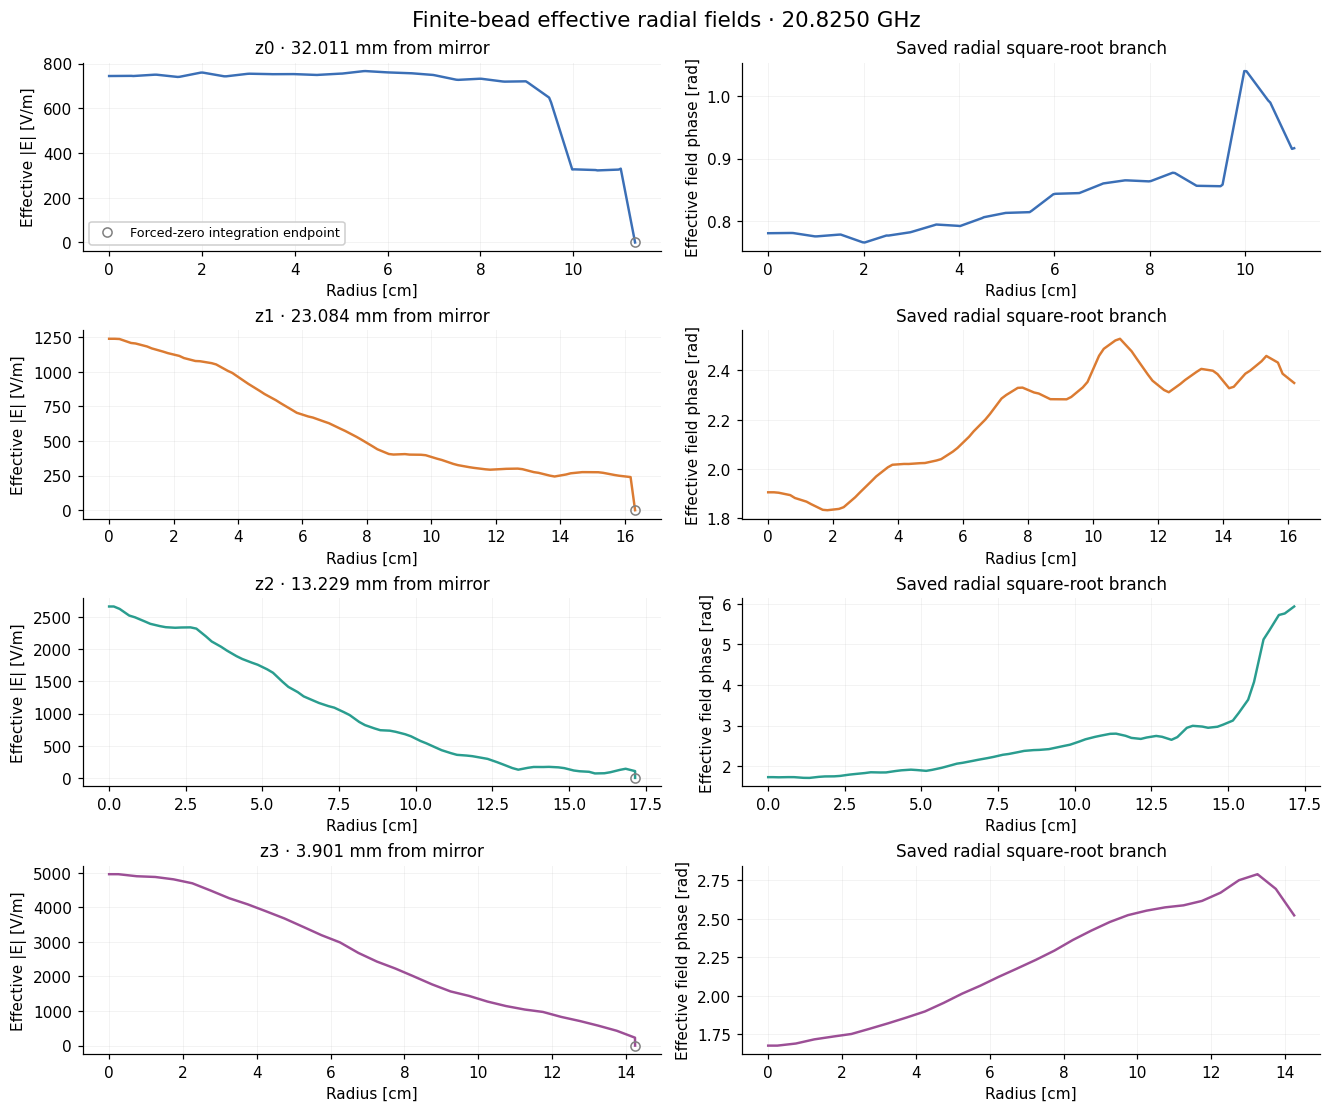

In [10]:
radial_fields_plot = partial(
    plots.plot_radial_fields,
    title="Finite-bead effective radial fields · {frequency_GHz:.4f} GHz",
    amplitude_title_template="{thread_name} · {z_mm:.3f} mm from mirror",
    phase_title="Saved radial square-root branch",
    x_label="Radius [cm]",
    amplitude_y_label="Effective |E| [V/m]",
    phase_y_label="Effective field phase [rad]",
    endpoint_label="Forced-zero integration endpoint",
)
plots.present(radial_fields_plot(data, FREQUENCY_GHZ), '06_radial_fields', FIGURE_DIR / 'measurement/transverse')

## 7. Transverse maps

Rotational continuation of each measured line.

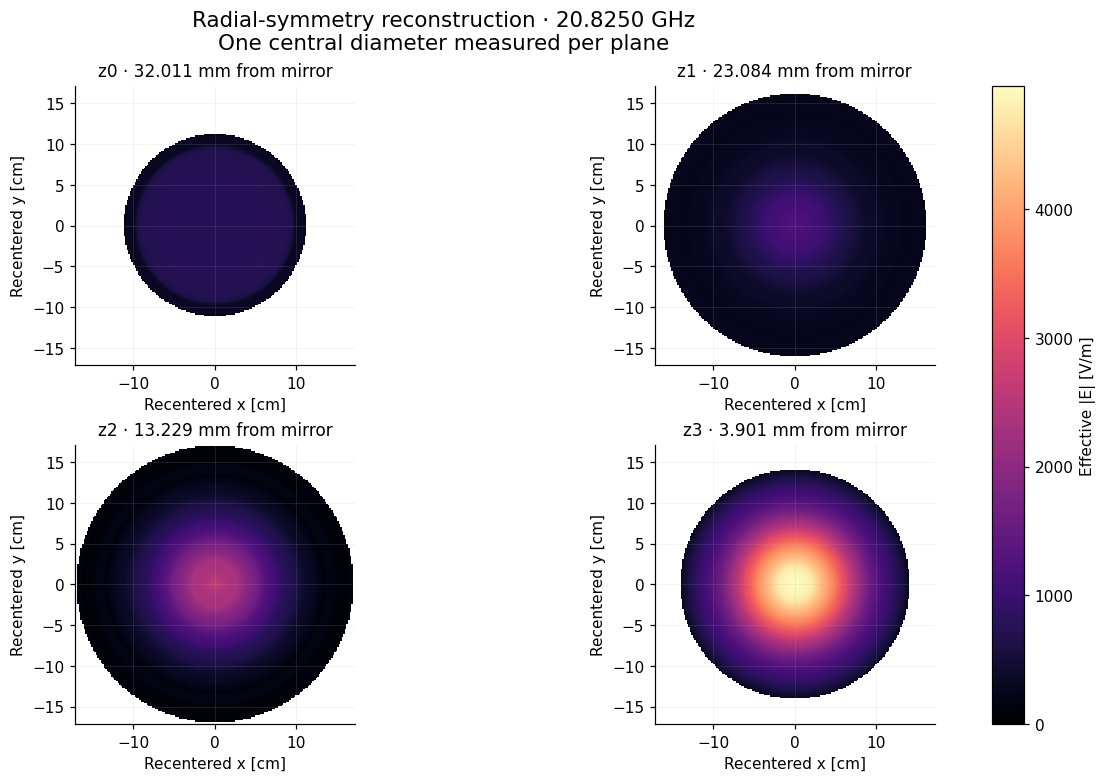

In [11]:
transverse_maps_plot = partial(
    plots.plot_transverse_maps,
    title="Radial-symmetry reconstruction · {frequency_GHz:.4f} GHz\nOne central diameter measured per plane",
    panel_title_template="{thread_name} · {z_mm:.3f} mm from mirror",
    x_label="Recentered x [cm]",
    y_label="Recentered y [cm]",
    colorbar_label="Effective |E| [V/m]",
)
plots.present(transverse_maps_plot(data, FREQUENCY_GHZ), '07_transverse_maps', FIGURE_DIR / 'measurement/transverse')

## 8. Transverse integration

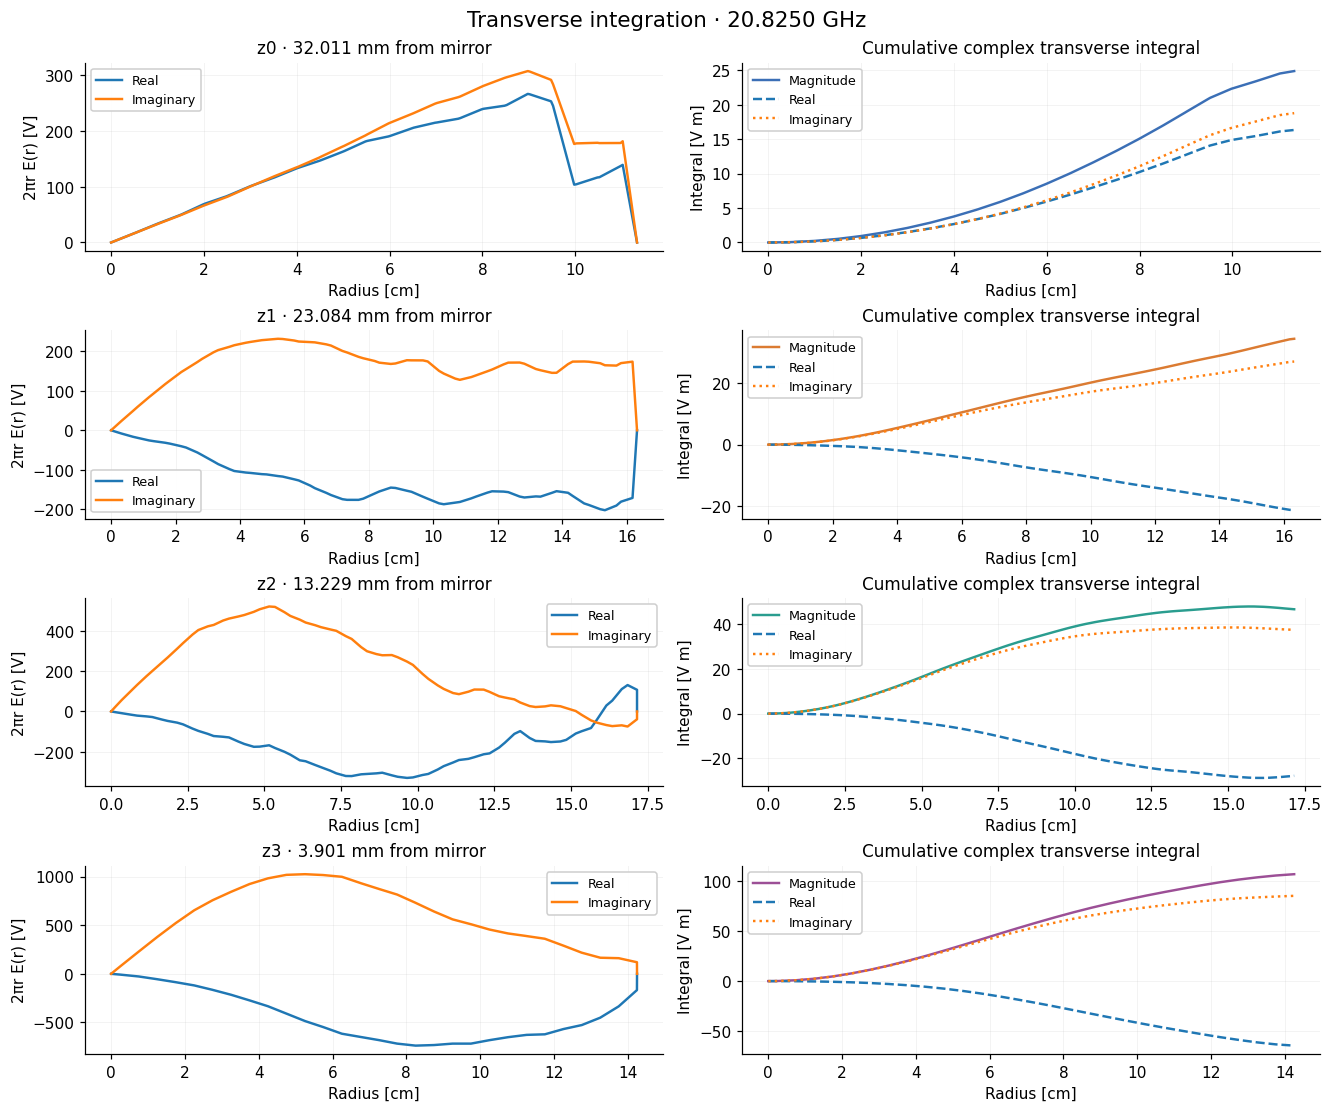

In [12]:
plots.present(
    plots.plot_radial_integration(
        data, FREQUENCY_GHZ,
        title="Transverse integration · {frequency_GHz:.4f} GHz",
        integrand_title_template="{thread_name} · {z_mm:.3f} mm from mirror",
        cumulative_title="Cumulative complex transverse integral",
        x_label="Radius [cm]",
        integrand_y_label="2πr E(r) [V]",
        cumulative_y_label="Integral [V m]",
        real_label="Real",
        imaginary_label="Imaginary",
        magnitude_label="Magnitude",
    ),
    '08_radial_integration', FIGURE_DIR / 'measurement/transverse',
)

## 9. Integrated fields

$E_T=\int E\,dA$, in V m. The 1D fit uses its magnitude.

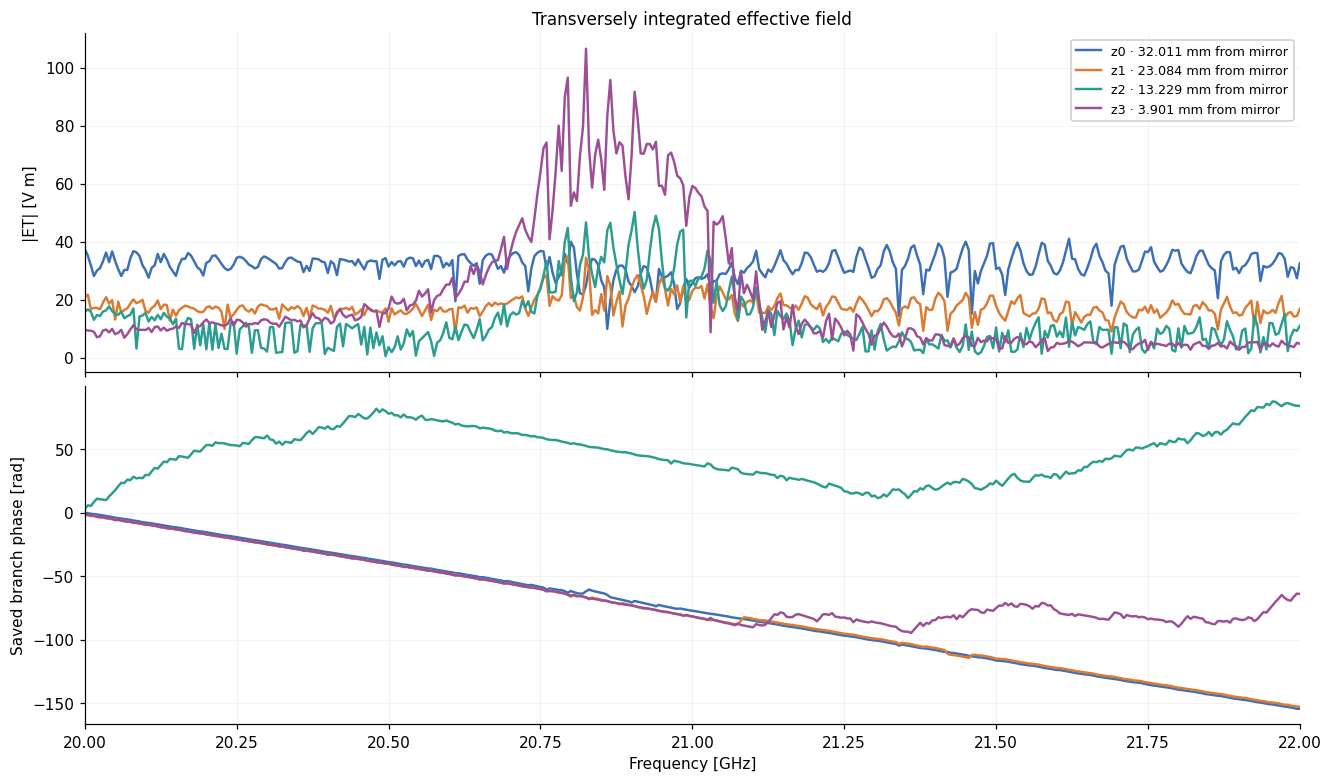

In [13]:
plots.present(
    plots.plot_integrated_fields(
        data,
        title="Transversely integrated effective field",
        phase_title="",
        x_label="Frequency [GHz]",
        amplitude_y_label="|ET| [V m]",
        phase_y_label="Saved branch phase [rad]",
        thread_label_template="{thread_name} · {z_mm:.3f} mm from mirror",
    ),
    '09_integrated_fields', FIGURE_DIR / 'measurement/transverse',
)

## 10. Radial phase cancellation

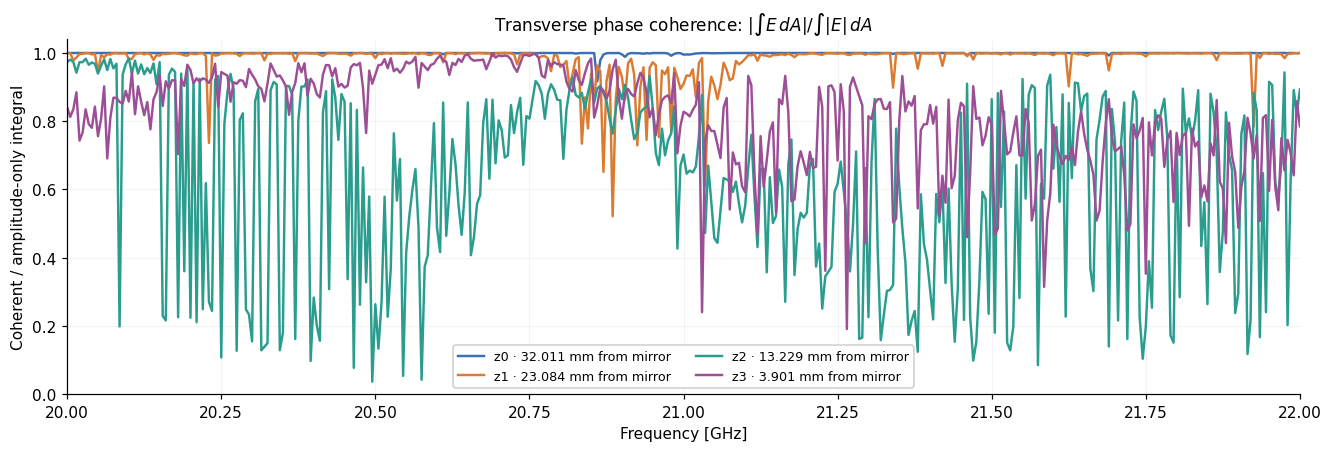

In [14]:
plots.present(
    plots.plot_transverse_coherence(
        data,
        title=r"Transverse phase coherence: $|\int E\,dA| / \int |E|\,dA$",
        x_label="Frequency [GHz]",
        y_label="Coherent / amplitude-only integral",
        thread_label_template="{thread_name} · {z_mm:.3f} mm from mirror",
    ),
    '10_transverse_coherence', FIGURE_DIR / 'measurement/transverse',
)

## 11. 1D fit

Measured magnitudes, finite-bead prediction, deconvolved model and residuals.

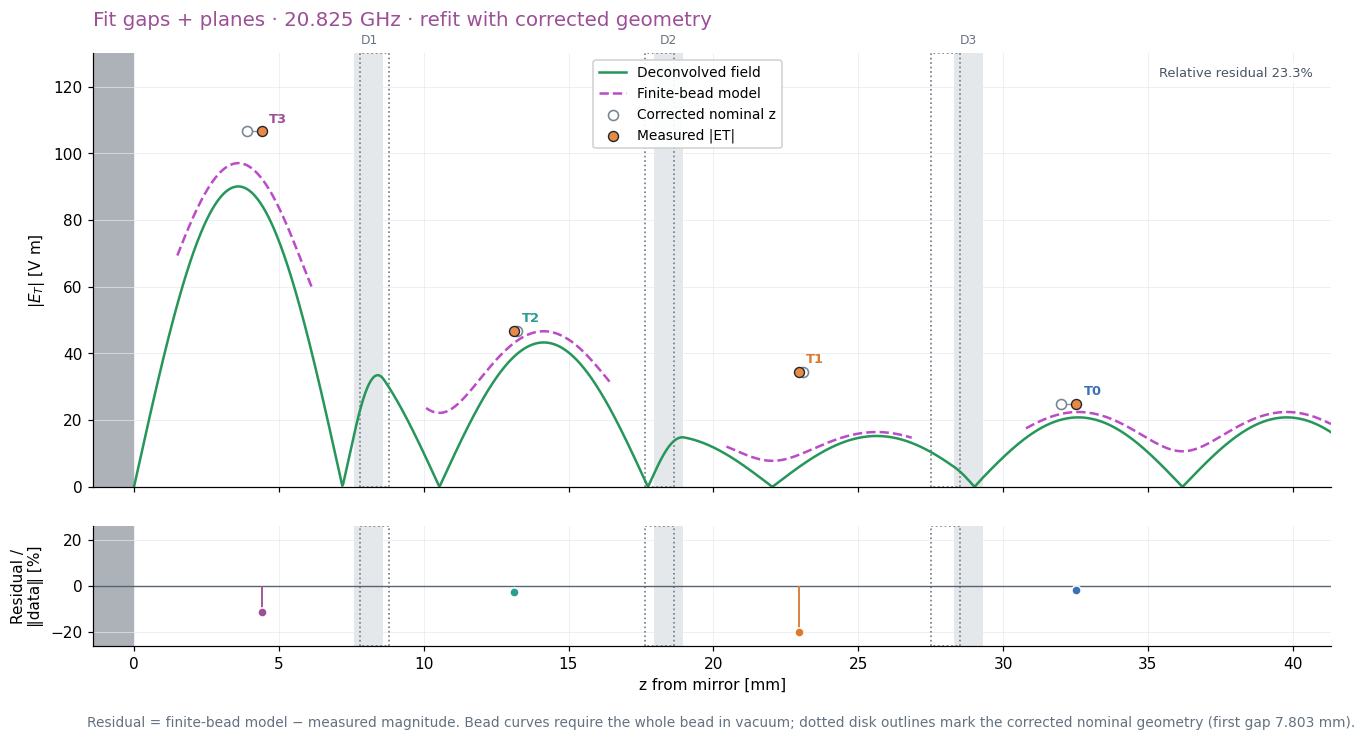

In [15]:
diagnostic_plot = partial(
    plots.plot_1d_diagnostic,
    title_template="{geometry_label} · {frequency_label} · refit with corrected geometry",
    x_label="z from mirror [mm]",
    y_label="$|E_T|$ [V m]",
    residual_y_label="Residual /\n‖data‖ [%]",
    true_field_label="Deconvolved field",
    bead_model_label="Finite-bead model",
    nominal_position_label="Corrected nominal z",
    measured_field_label="Measured |ET|",
    disk_label_template="D{disk_index}",
    thread_label_template="T{thread_index}",
    residual_annotation_template="Relative residual {residual_percent:.1f}%",
    geometry_labels={"fixed": "Fixed geometry", "gaps": "Fit gaps", "positions": "Fit plane positions", "both": "Fit gaps + planes"},
    frequency_label_template="{frequency_GHz:.6g} GHz",
    nearest_frequency_label_template="{frequency_GHz:.6g} GHz (nearest to {requested_frequency_GHz:.6g} GHz)",
    footnote="Residual = finite-bead model − measured magnitude. Bead curves require the whole bead in vacuum; dotted disk outlines mark the corrected nominal geometry (first gap 7.803 mm).",
)
plots.present(diagnostic_plot(data, FREQUENCY_GHZ, GEOMETRY), '11_1d_diagnostic', FIGURE_DIR / GEOMETRY / 'fits')

## 12. Geometry choices

Fixed, gaps, thread z, or both; shared geometry across frequency.

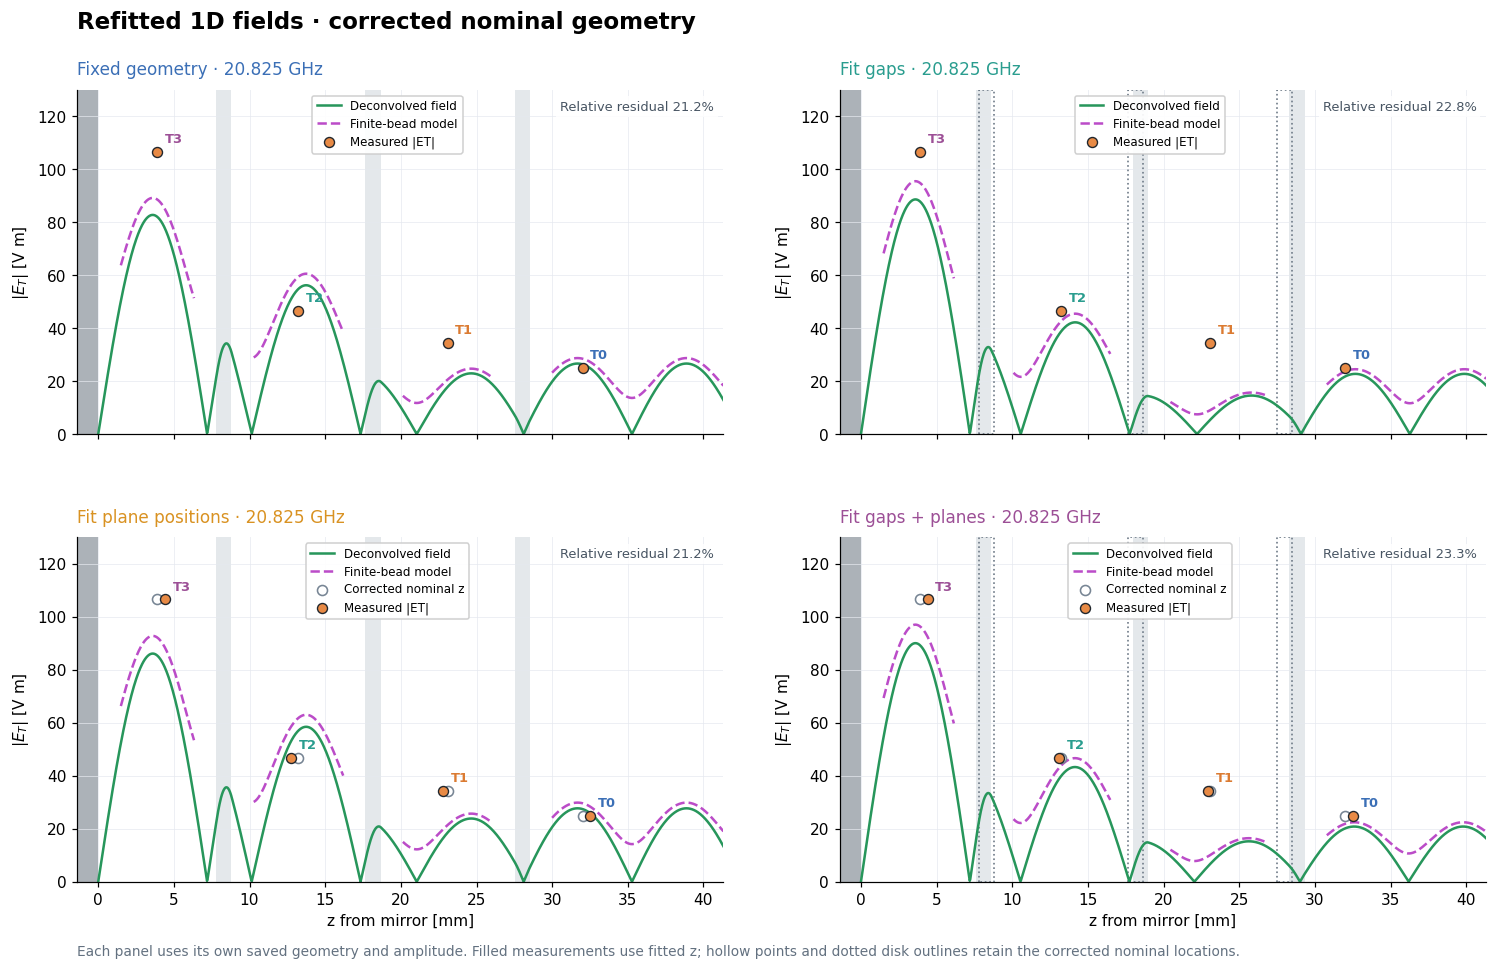

In [16]:
plots.present(
    plots.plot_1d_comparison(
        data, FREQUENCY_GHZ,
        title="Refitted 1D fields · corrected nominal geometry",
        panel_title_template="{geometry_label} · {frequency_label}",
        x_label="z from mirror [mm]",
        y_label="$|E_T|$ [V m]",
        true_field_label="Deconvolved field",
        bead_model_label="Finite-bead model",
        nominal_position_label="Corrected nominal z",
        measured_field_label="Measured |ET|",
        thread_label_template="T{thread_index}",
        residual_annotation_template="Relative residual {residual_percent:.1f}%",
        geometry_labels={"fixed": "Fixed geometry", "gaps": "Fit gaps", "positions": "Fit plane positions", "both": "Fit gaps + planes"},
        frequency_label_template="{frequency_GHz:.6g} GHz",
        nearest_frequency_label_template="{frequency_GHz:.6g} GHz (nearest to {requested_frequency_GHz:.6g} GHz)",
        missing_fit_template="{geometry_label}\nNo saved result",
        footnote="Each panel uses its own saved geometry and amplitude. Filled measurements use fitted z; hollow points and dotted disk outlines retain the corrected nominal locations.",
    ),
    '12_1d_comparison', FIGURE_DIR / 'geometry_comparison/fits',
)

## 13. Longitudinal field

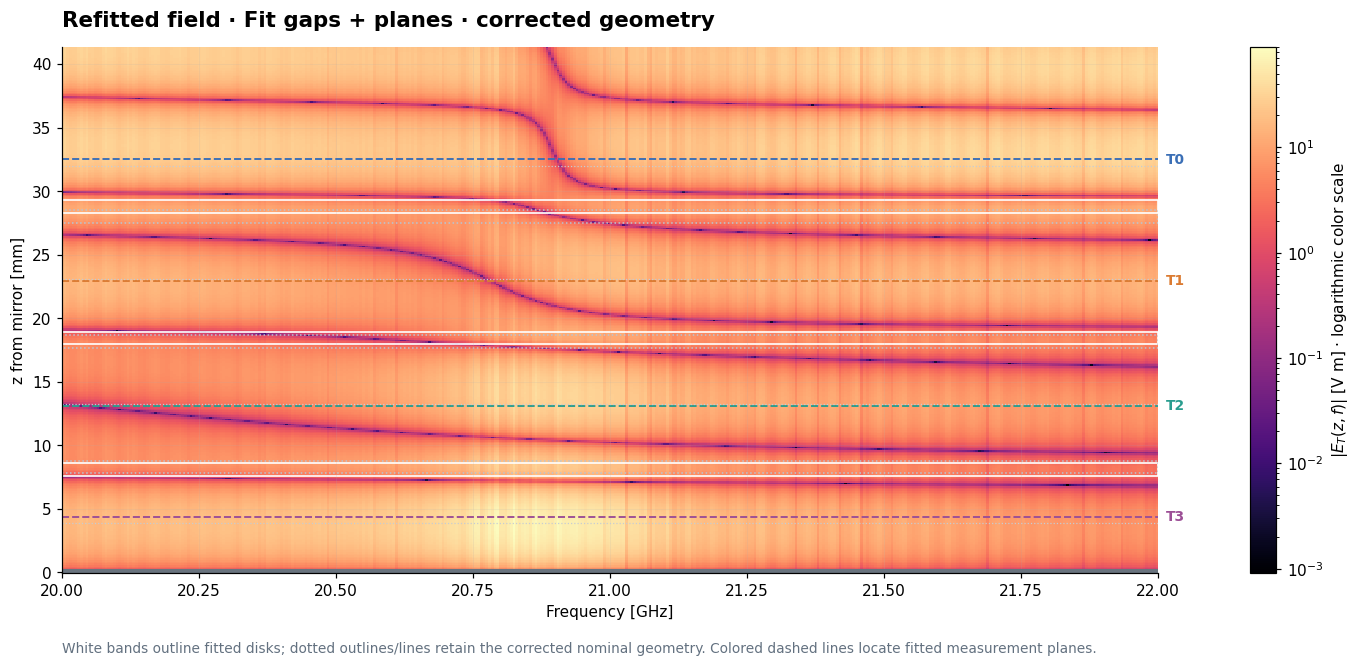

In [17]:
plots.present(
    plots.plot_1d_field_map(
        data, GEOMETRY,
        logarithmic=True,
        title_template="Refitted field · {geometry_label} · corrected geometry",
        x_label="Frequency [GHz]",
        y_label="z from mirror [mm]",
        colorbar_label="$|E_T(z,f)|$ [V m]",
        logarithmic_colorbar_suffix=" · logarithmic color scale",
        thread_label_template="T{thread_index}",
        geometry_labels={"fixed": "Fixed geometry", "gaps": "Fit gaps", "positions": "Fit plane positions", "both": "Fit gaps + planes"},
        footnote="White bands outline fitted disks; dotted outlines/lines retain the corrected nominal geometry. Colored dashed lines locate fitted measurement planes.",
    ),
    '13_1d_field_map', FIGURE_DIR / GEOMETRY / 'fields',
)

## 14. Resonance field

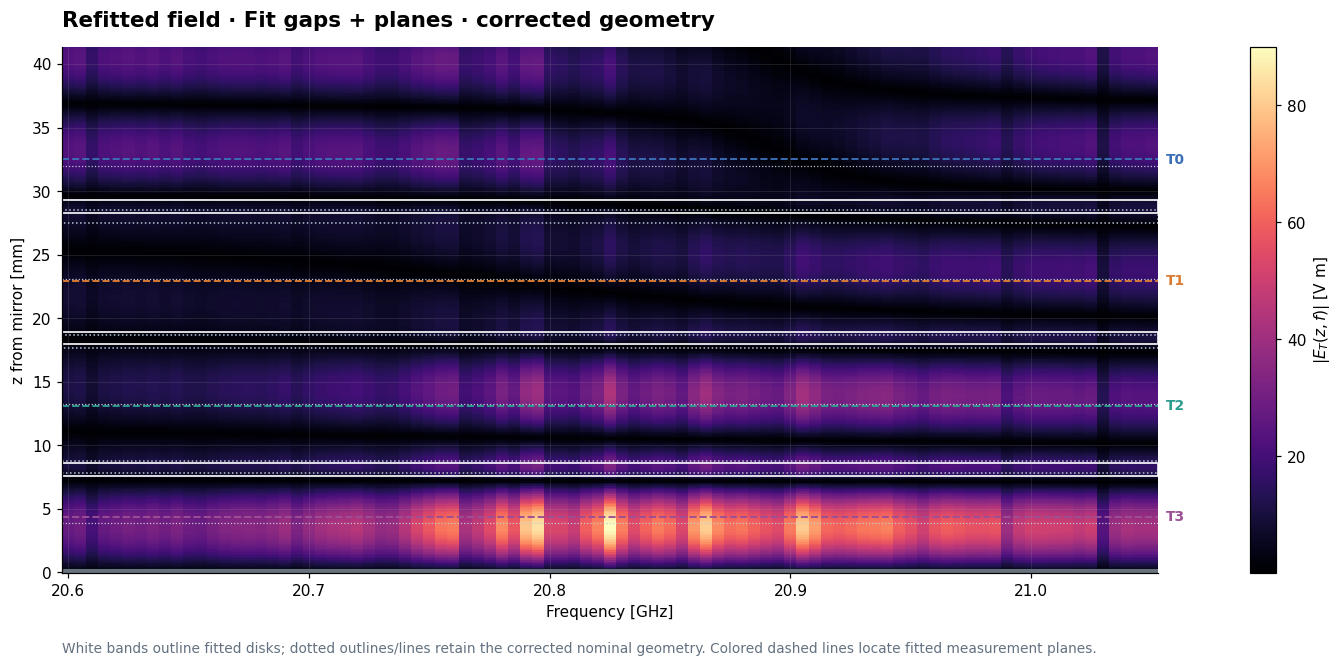

In [18]:
plots.present(
    plots.plot_1d_field_map(
        data, GEOMETRY,
        frequency_range_GHz=ZOOM_GHZ,
        title_template="Refitted field · {geometry_label} · corrected geometry",
        x_label="Frequency [GHz]",
        y_label="z from mirror [mm]",
        colorbar_label="$|E_T(z,f)|$ [V m]",
        logarithmic_colorbar_suffix=" · logarithmic color scale",
        thread_label_template="T{thread_index}",
        geometry_labels={"fixed": "Fixed geometry", "gaps": "Fit gaps", "positions": "Fit plane positions", "both": "Fit gaps + planes"},
        footnote="White bands outline fitted disks; dotted outlines/lines retain the corrected nominal geometry. Colored dashed lines locate fitted measurement planes.",
    ),
    '14_1d_field_map_zoom', FIGURE_DIR / GEOMETRY / 'fields',
)

## 15. Geometry shifts

Dashed bounds are optimization limits, not uncertainties.

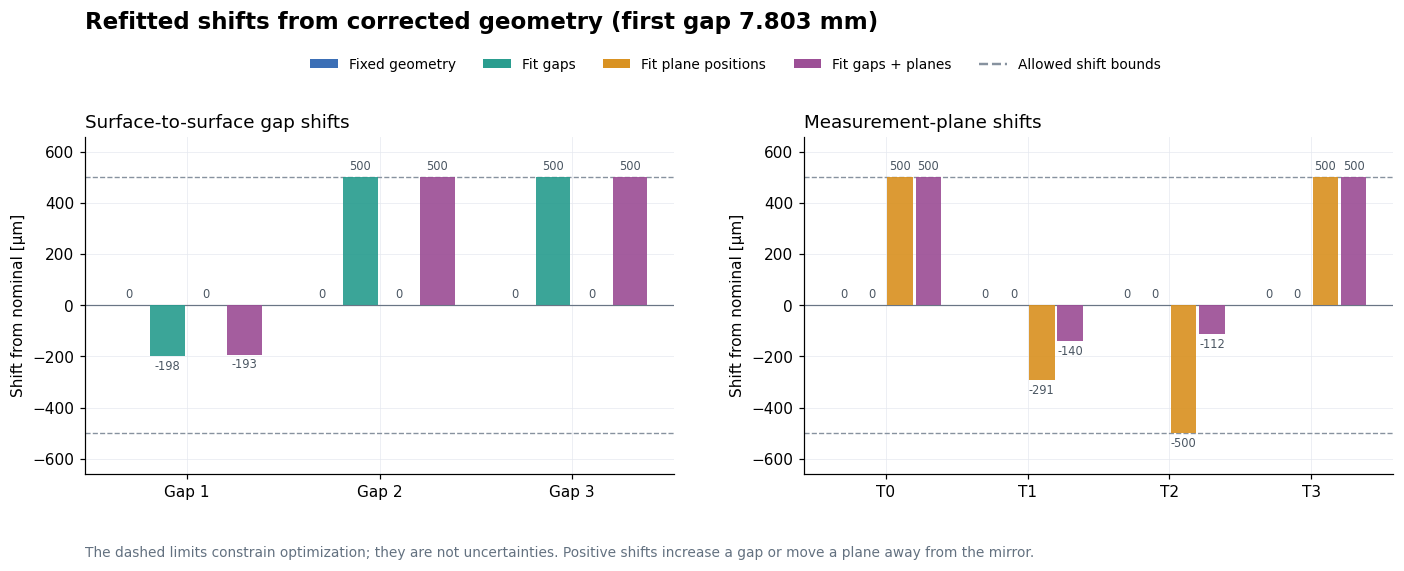

In [19]:
plots.present(
    plots.plot_geometry_shifts(
        data,
        title="Refitted shifts from corrected geometry (first gap 7.803 mm)",
        gap_panel_title="Surface-to-surface gap shifts",
        position_panel_title="Measurement-plane shifts",
        y_label="Shift from nominal [µm]",
        gap_tick_template="Gap {gap_index}",
        thread_tick_template="T{thread_index}",
        value_annotation_template="{shift_um:.0f}",
        zero_shift_label="0",
        geometry_labels={"fixed": "Fixed geometry", "gaps": "Fit gaps", "positions": "Fit plane positions", "both": "Fit gaps + planes"},
        bound_label="Allowed shift bounds",
        footnote="The dashed limits constrain optimization; they are not uncertainties. Positive shifts increase a gap or move a plane away from the mirror.",
    ),
    '15_geometry_shifts', FIGURE_DIR / 'geometry_comparison/geometry',
)

## 16. Boost and residuals

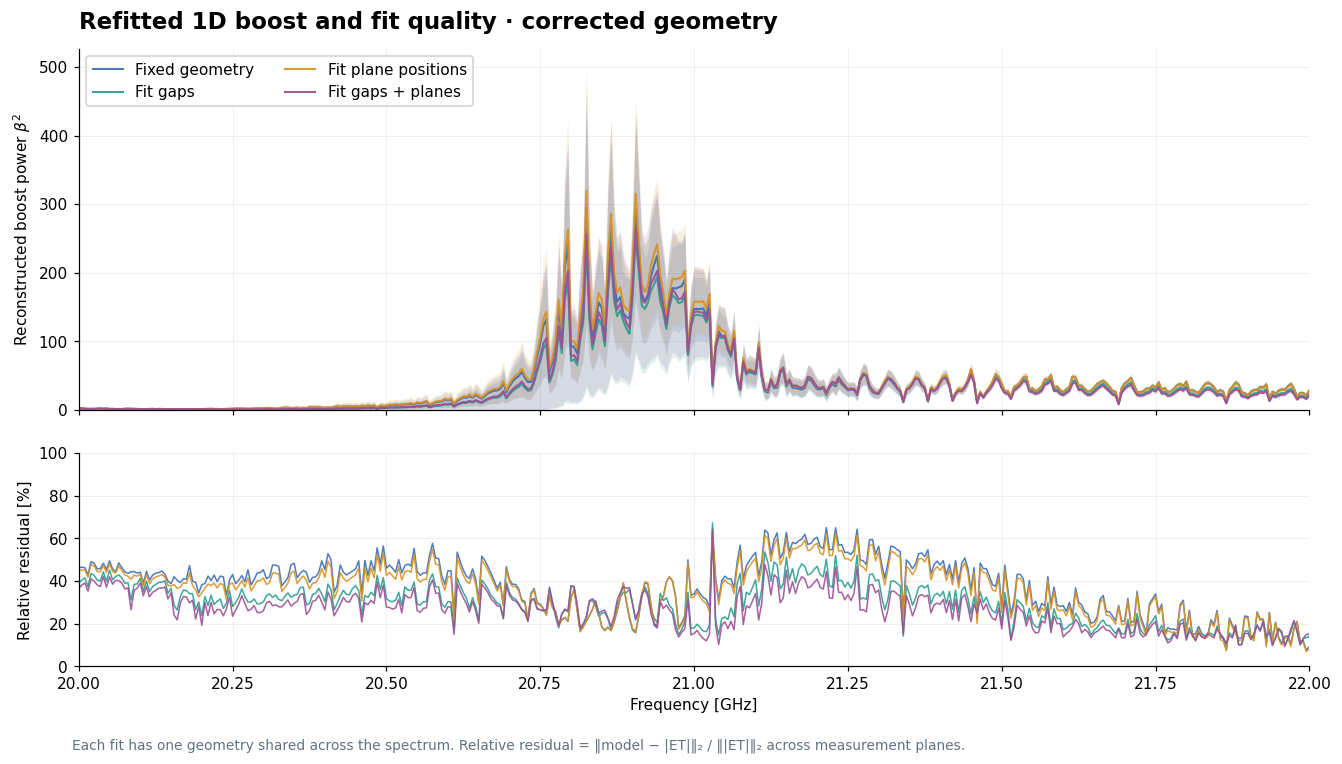

In [20]:
plots.present(
    plots.plot_fit_spectra(
        data,
        title="Refitted 1D boost and fit quality · corrected geometry",
        x_label="Frequency [GHz]",
        boost_y_label=r"Reconstructed boost power $\beta^2$",
        residual_y_label="Relative residual [%]",
        geometry_labels={"fixed": "Fixed geometry", "gaps": "Fit gaps", "positions": "Fit plane positions", "both": "Fit gaps + planes"},
        footnote="Each fit has one geometry shared across the spectrum. Relative residual = ‖model − |ET|‖₂ / ‖|ET|‖₂ across measurement planes.",
    ),
    '16_1d_boost_spectra', FIGURE_DIR / 'geometry_comparison/boost',
)

## 17. Resonance zoom

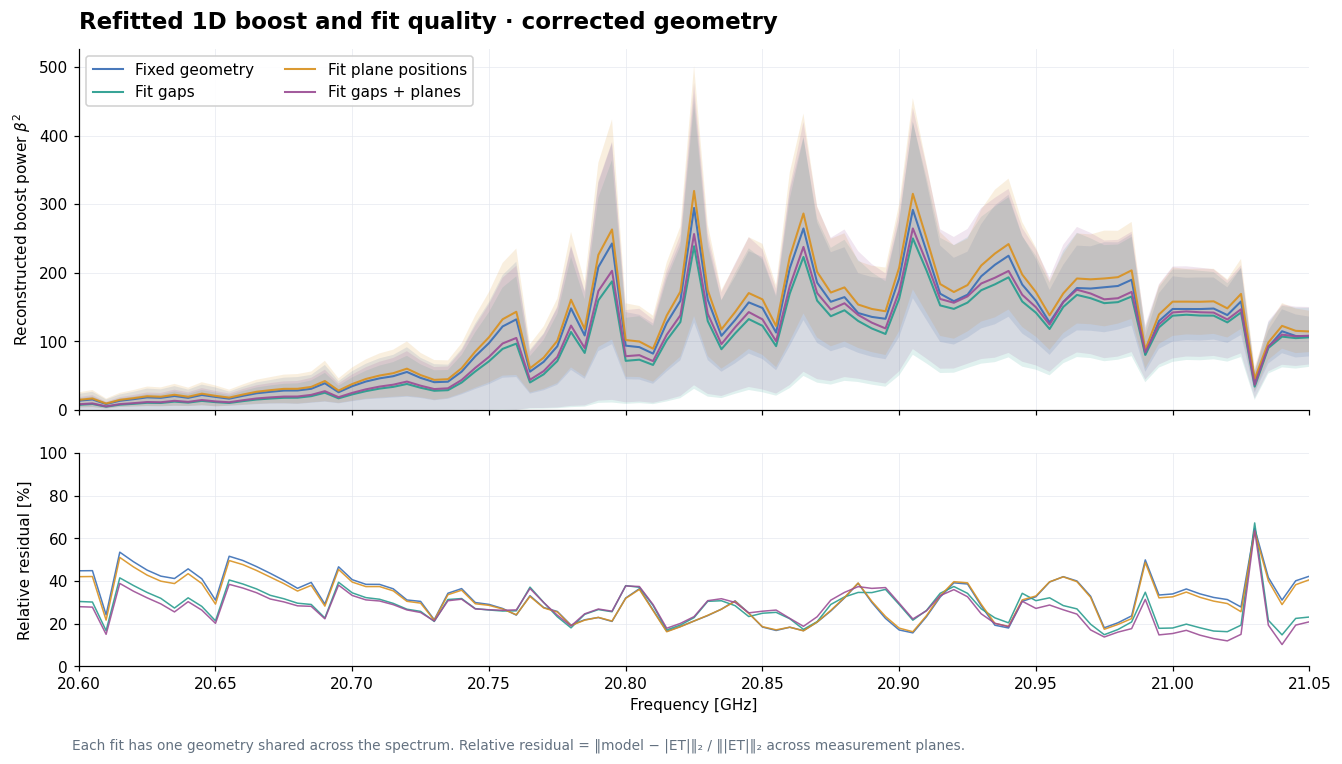

In [21]:
plots.present(
    plots.plot_fit_spectra(
        data,
        frequency_range_GHz=ZOOM_GHZ,
        title="Refitted 1D boost and fit quality · corrected geometry",
        x_label="Frequency [GHz]",
        boost_y_label=r"Reconstructed boost power $\beta^2$",
        residual_y_label="Relative residual [%]",
        geometry_labels={"fixed": "Fixed geometry", "gaps": "Fit gaps", "positions": "Fit plane positions", "both": "Fit gaps + planes"},
        footnote="Each fit has one geometry shared across the spectrum. Relative residual = ‖model − |ET|‖₂ / ‖|ET|‖₂ across measurement planes.",
    ),
    '17_1d_boost_zoom', FIGURE_DIR / 'geometry_comparison/boost',
)

## 17a. Earlier calculation

Solid: new pipeline, 20–22 GHz, 7.803 mm first gap. Dashed: archived earlier calculation, 12–22 GHz, 8.803 mm first gap. Several analysis settings differ.

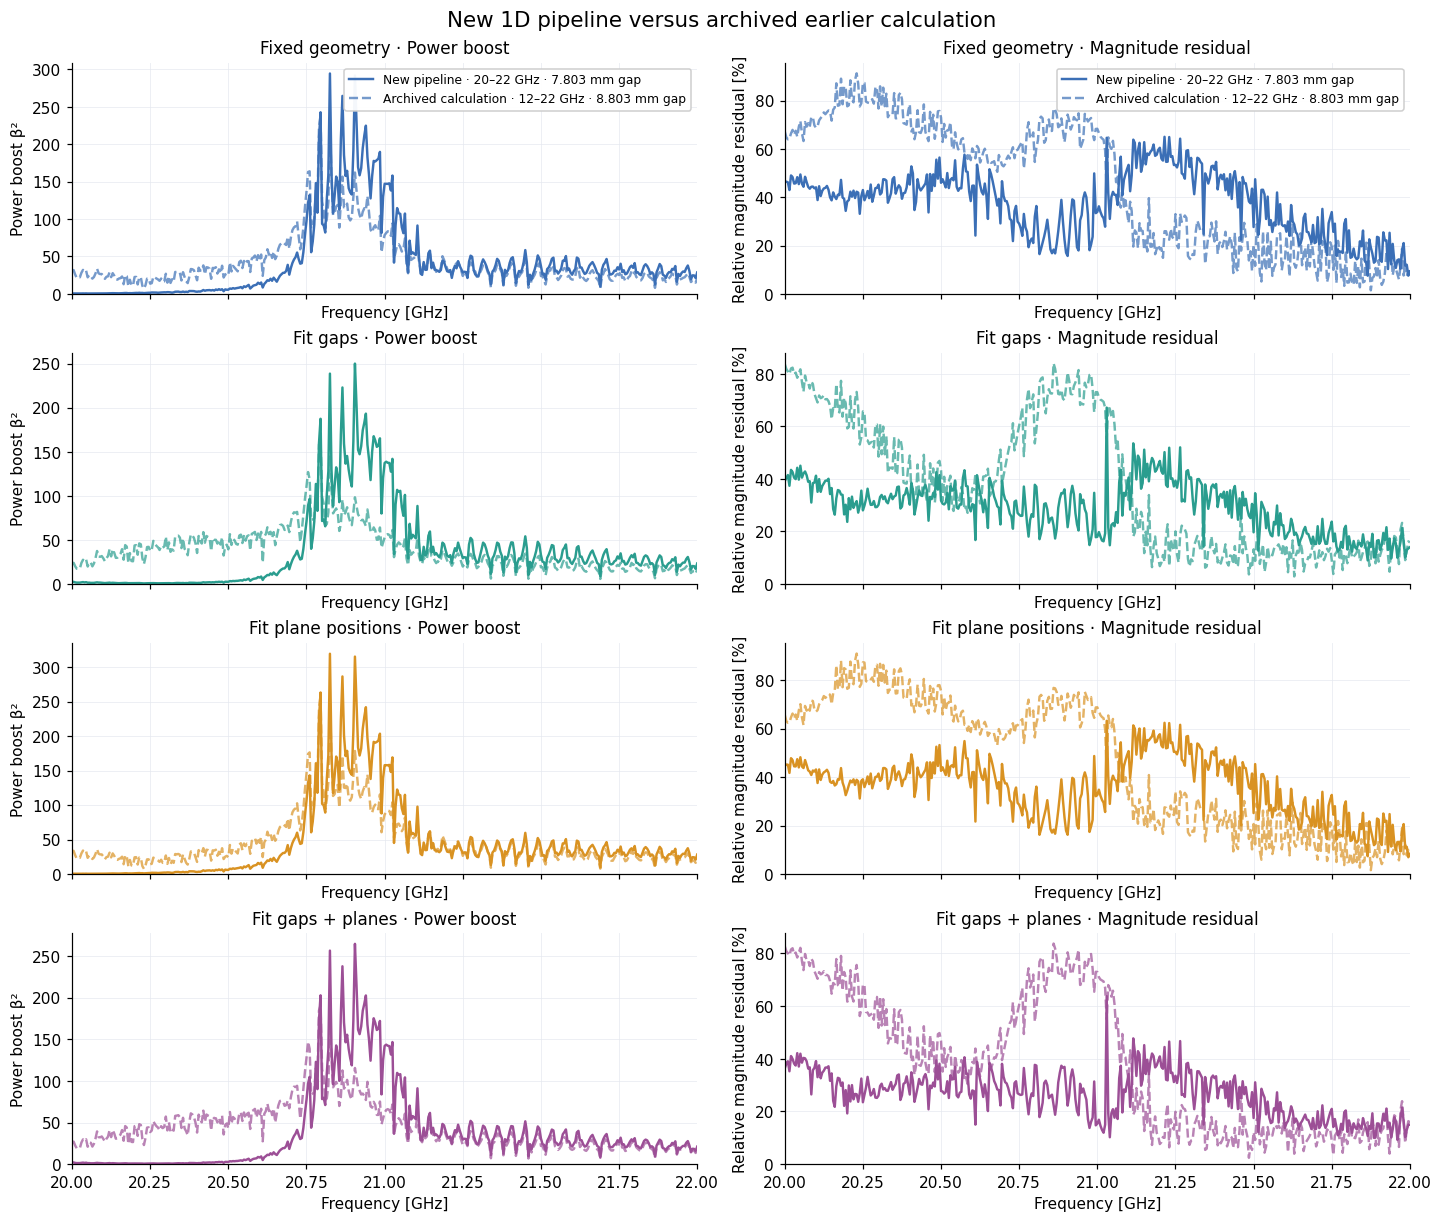

In [22]:
plots.present(
    plots.plot_1d_refit_comparison(
        data, PREVIOUS_1D_DIR,
        title="New 1D pipeline versus archived earlier calculation",
        panel_title_template="{geometry_label} · {quantity_label}",
        x_label="Frequency [GHz]",
        boost_y_label="Power boost β²",
        residual_y_label="Relative magnitude residual [%]",
        current_label="New pipeline · 20–22 GHz · {current_gap_mm:.3f} mm gap",
        previous_label="Archived calculation · 12–22 GHz · {previous_gap_mm:.3f} mm gap",
        boost_panel_label="Power boost",
        residual_panel_label="Magnitude residual",
        geometry_labels={"fixed": "Fixed geometry", "gaps": "Fit gaps", "positions": "Fit plane positions", "both": "Fit gaps + planes"},
    ),
    '30_1d_refit_comparison', FIGURE_DIR / 'geometry_comparison/history',
)

## 18. Residuals by thread

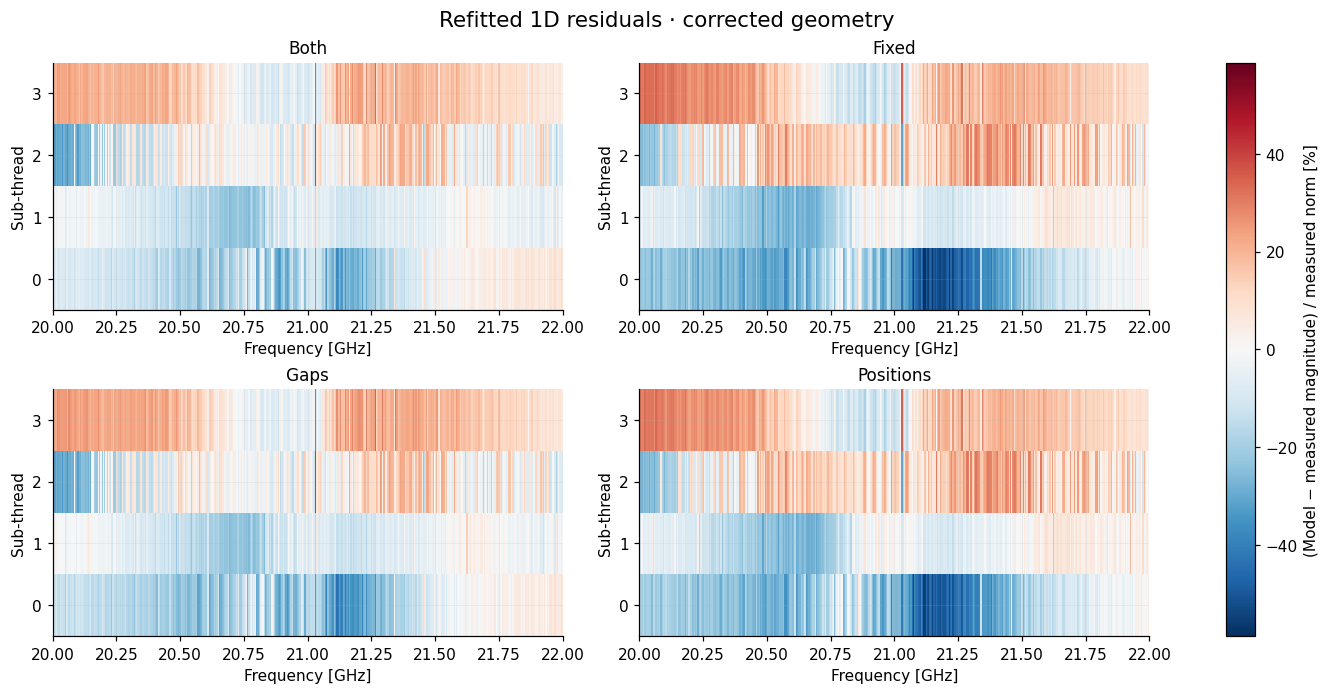

In [23]:
plots.present(
    plots.plot_1d_residual_map(
        data,
        title="Refitted 1D residuals · corrected geometry",
        x_label="Frequency [GHz]",
        y_label="Sub-thread",
        colorbar_label="(Model − measured magnitude) / measured norm [%]",
        fixed_panel_title="Fixed",
        gaps_panel_title="Gaps",
        positions_panel_title="Positions",
        both_panel_title="Both",
        thread_tick_template="{thread_index}",
        missing_title="No saved 1D fits",
        missing_message="Run src.fit_1D on integrated_fields.npz first.",
    ),
    '18_1d_residual_maps', FIGURE_DIR / 'geometry_comparison/residuals',
)

## 19. Independent beam reference

Beam-scan z is not registered to the spider mirror.

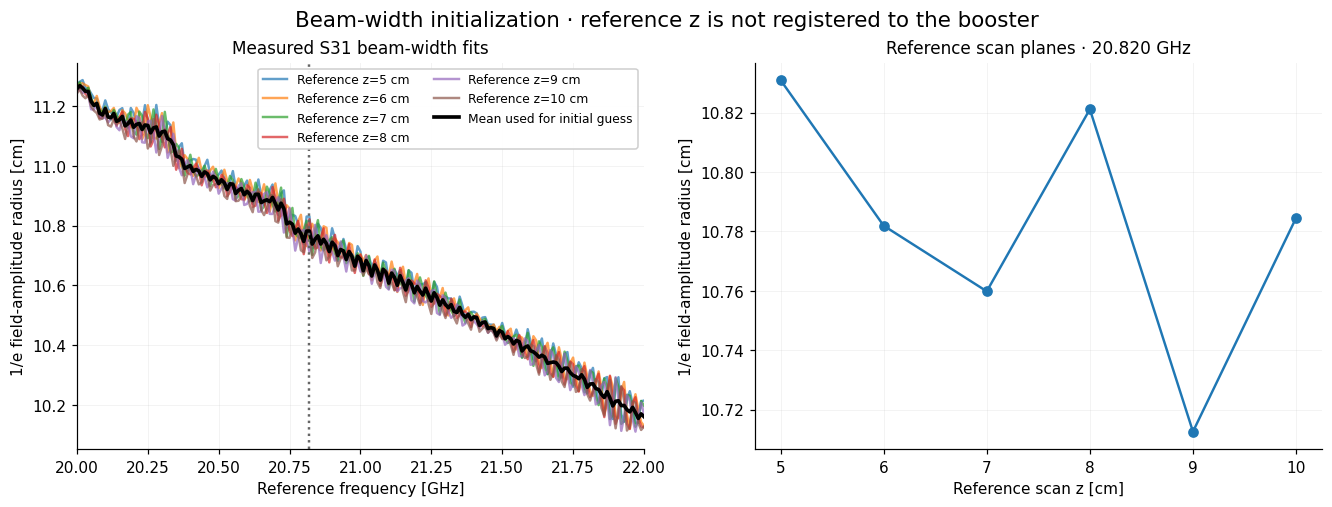

In [24]:
plots.present(
    plots.plot_beam_reference(
        data, FREQUENCY_GHZ,
        title="Beam-width initialization · reference z is not registered to the booster",
        spectrum_title="Measured S31 beam-width fits",
        planes_title="Reference scan planes · {frequency_GHz:.3f} GHz",
        frequency_x_label="Reference frequency [GHz]",
        position_x_label="Reference scan z [cm]",
        y_label="1/e field-amplitude radius [cm]",
        reference_label_template="Reference z={z_cm:.0f} cm",
        mean_label="Mean used for initial guess",
    ),
    '19_beam_reference', FIGURE_DIR / 'measurement/incident_beam',
)

## 20. Full bead-pull comparison

Reference: 20.5–21.5 GHz. Saved normalizations differ; no absolute calibration alignment is assumed.

In [25]:
from src import full_bead_comparison as comparison

full_bead = comparison.load_full_bead(FULL_BEAD_FILE)
COMPARISON_DIR = FIGURE_DIR / "full_bead_comparison" / GEOMETRY

In [26]:
comparison.normalization_summary(full_bead, compact=True)
comparison.comparison_summary(data, full_bead, COMPARISON_GHZ, compact=True)

**Normalization:** full-reference β² carries a factor 20.1613–20.1613 relative to the spider convention. Physical correction factors are unknown; no rescaling is applied.

**Reference:** 20.5–21.5 GHz · comparison at 21.0000 GHz. Values retain saved normalizations.

,Saved β² at selected f,Peak f in overlap [GHz],Saved peak β²,Magnitude residual [%],Measured z planes
Result,,,,,
Spider 1D · both,141.9857,20.905,264.5171,15.3770,4
Spider 1D · fixed,147.0363,20.825,294.4069,33.9188,4
Spider 1D · gaps,137.2577,20.905,249.9722,17.9623,4
Spider 1D · positions,157.7131,20.825,319.1836,32.5680,4
Full bead pull · saved MC result,74.9399,20.816,480.4751,5.9972,28


### Boost factor

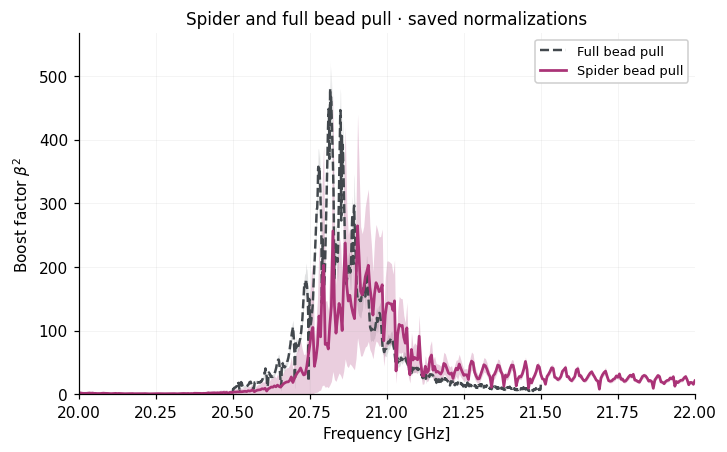

In [27]:
plots.present(
    comparison.plot_boost_comparison(
        data, full_bead,
        title="Spider and full bead pull · saved normalizations",
        x_label="Frequency [GHz]",
        y_label="Boost factor $\\beta^2$",
        full_curve_label="Full bead pull",
        spider_curve_label="Spider bead pull",
    ),
    '22_boost_comparison', COMPARISON_DIR,
)

### Fields at 21 GHz

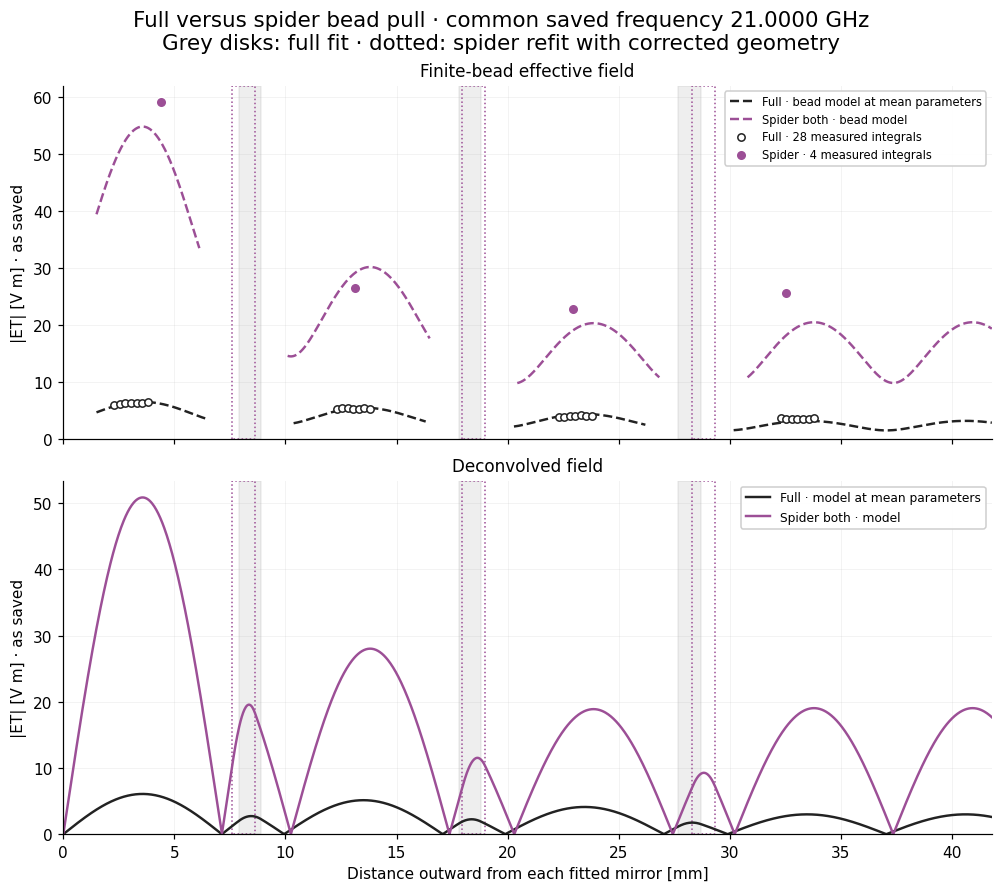

In [28]:
plots.present(
    comparison.plot_field_comparison(
        data, full_bead, COMPARISON_GHZ, GEOMETRY,
        title="Full versus spider bead pull · common saved frequency {frequency_GHz:.4f} GHz\nGrey disks: full fit · dotted: spider refit with corrected geometry",
        x_label="Distance outward from each fitted mirror [mm]",
        y_label="|ET| [V m] · as saved",
        effective_field_title="Finite-bead effective field",
        deconvolved_field_title="Deconvolved field",
        full_bead_label="Full · bead model at mean parameters",
        spider_bead_label_template="Spider {geometry} · bead model",
        full_measured_label_template="Full · {n_full} measured integrals",
        spider_measured_label_template="Spider · {n_spider} measured integrals",
        full_field_label="Full · model at mean parameters",
        spider_field_label_template="Spider {geometry} · model",
    ),
    '23_field_comparison_21ghz', COMPARISON_DIR,
)

### Fields near the reference resonance

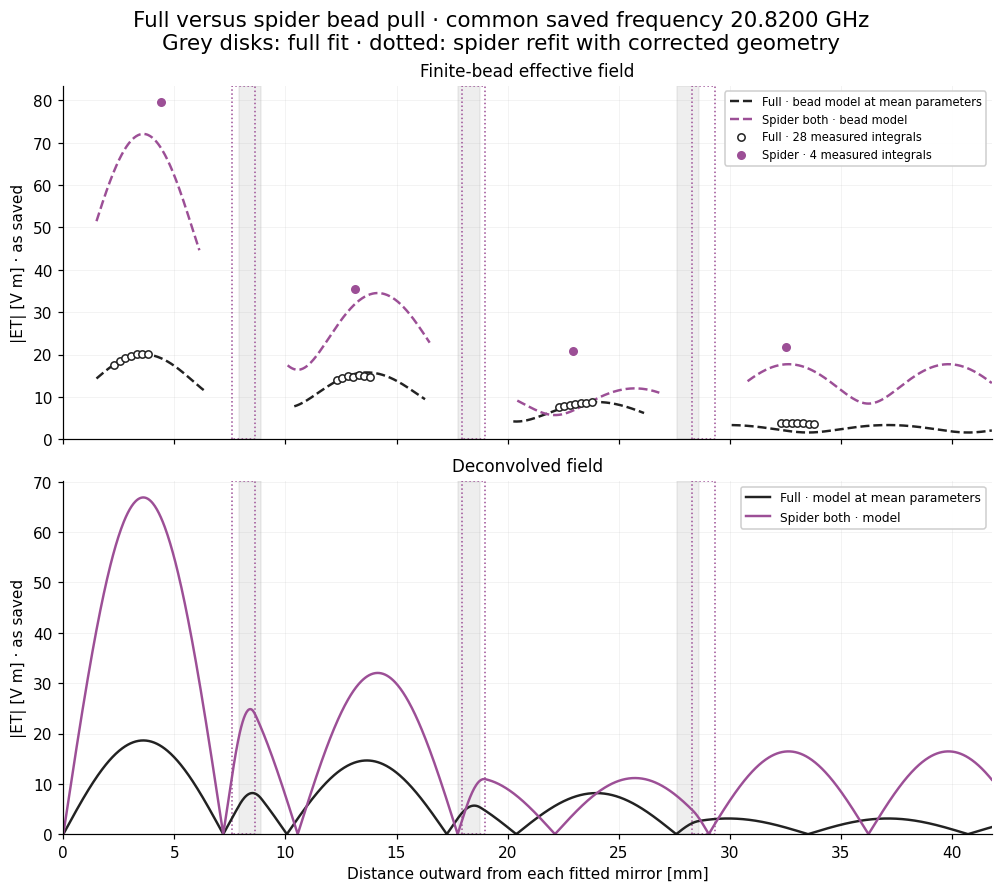

In [29]:
plots.present(
    comparison.plot_field_comparison(
        data, full_bead, comparison.reference_peak_frequency(data, full_bead), GEOMETRY,
        title="Full versus spider bead pull · common saved frequency {frequency_GHz:.4f} GHz\nGrey disks: full fit · dotted: spider refit with corrected geometry",
        x_label="Distance outward from each fitted mirror [mm]",
        y_label="|ET| [V m] · as saved",
        effective_field_title="Finite-bead effective field",
        deconvolved_field_title="Deconvolved field",
        full_bead_label="Full · bead model at mean parameters",
        spider_bead_label_template="Spider {geometry} · bead model",
        full_measured_label_template="Full · {n_full} measured integrals",
        spider_measured_label_template="Spider · {n_spider} measured integrals",
        full_field_label="Full · model at mean parameters",
        spider_field_label_template="Spider {geometry} · model",
    ),
    '24_field_comparison_resonance', COMPARISON_DIR,
)

### Geometry and sampling

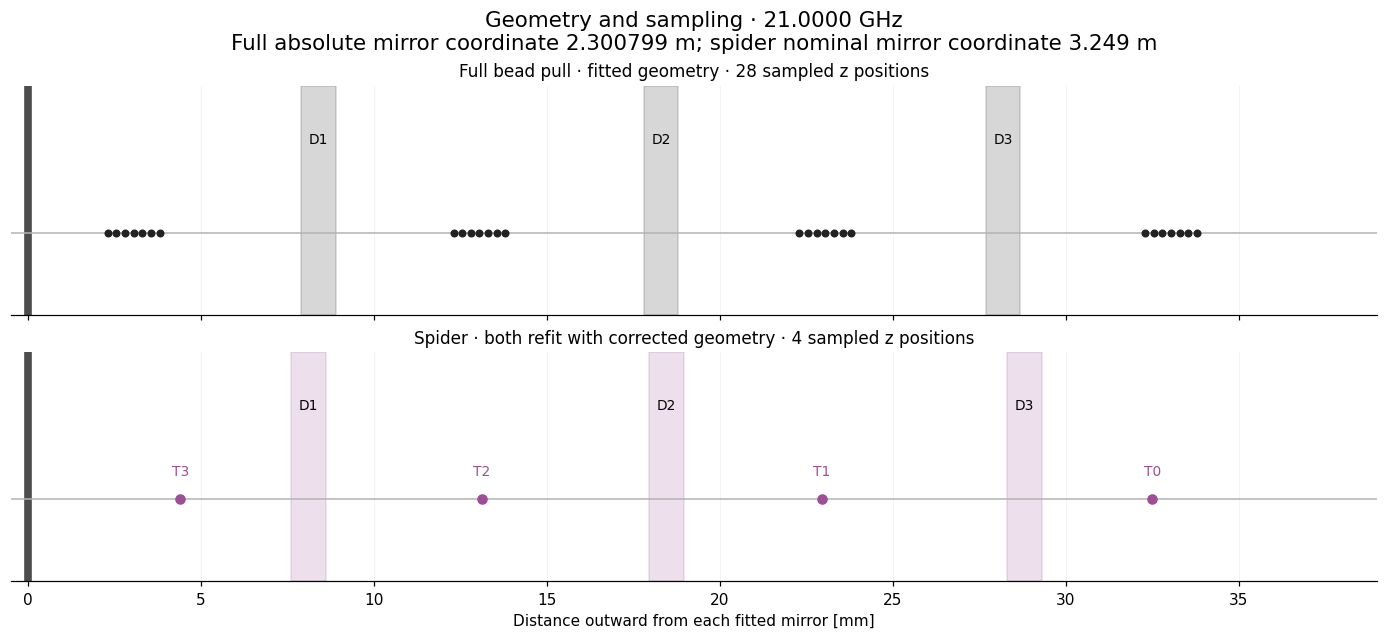

In [30]:
plots.present(
    comparison.plot_geometry_comparison(
        data, full_bead, COMPARISON_GHZ, GEOMETRY,
        title="Geometry and sampling · {frequency_GHz:.4f} GHz\nFull absolute mirror coordinate {full_mirror_z_m:.6f} m; spider nominal mirror coordinate {spider_mirror_z_m:.3f} m",
        x_label="Distance outward from each fitted mirror [mm]",
        full_panel_title_template="Full bead pull · fitted geometry · {n_positions} sampled z positions",
        spider_panel_title_template="Spider · {geometry} refit with corrected geometry · {n_positions} sampled z positions",
        disk_label_template="D{disk_index}",
        thread_label_template="T{thread_index}",
    ),
    '25_geometry_comparison', COMPARISON_DIR,
)

### Fitted gaps

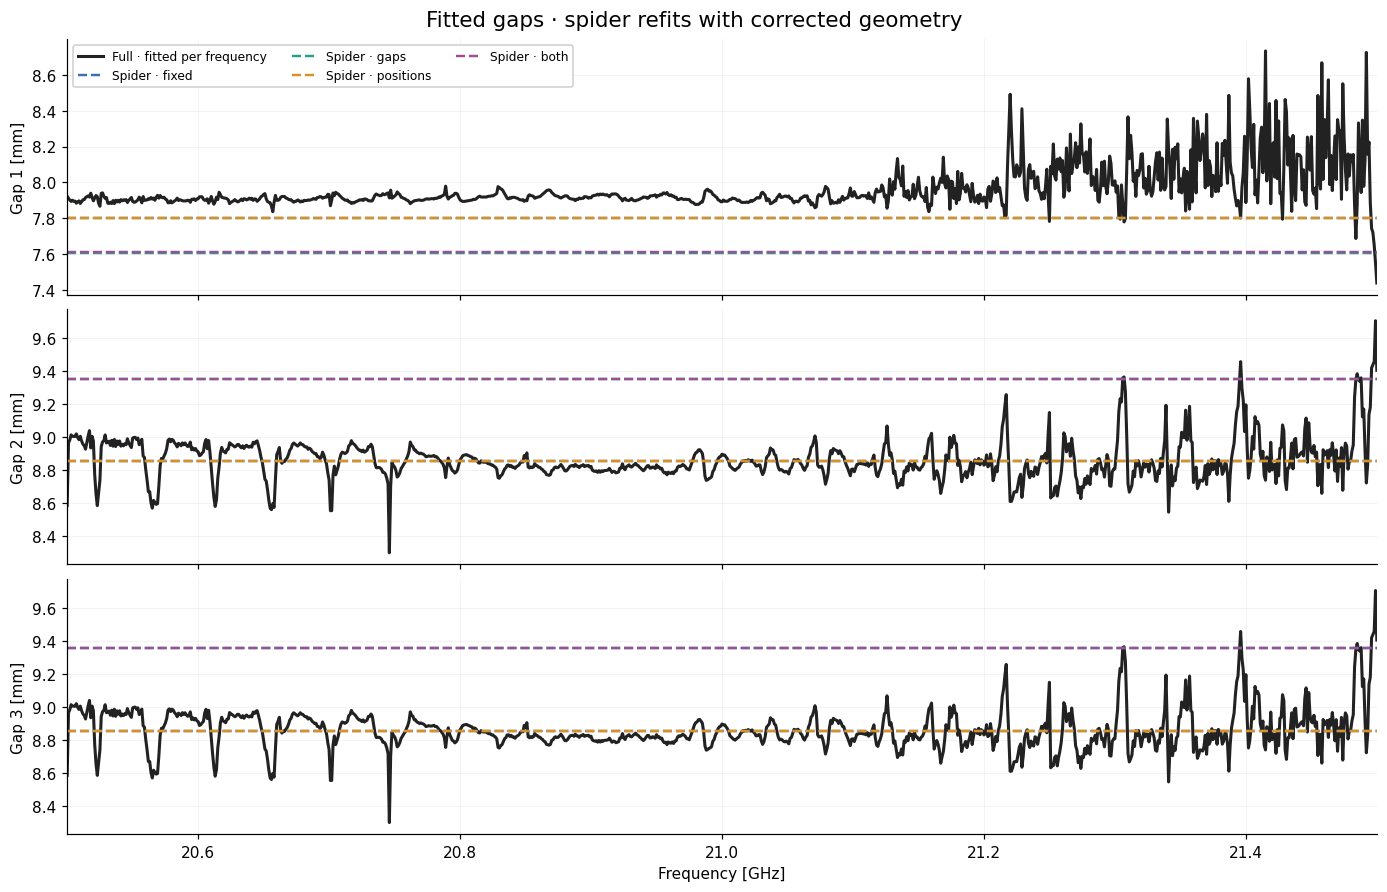

In [31]:
plots.present(
    comparison.plot_gap_comparison(
        data, full_bead,
        title="Fitted gaps · spider refits with corrected geometry",
        x_label="Frequency [GHz]",
        y_label_template="Gap {gap_index} [mm]",
        full_curve_label="Full · fitted per frequency",
        spider_curve_label_template="Spider · {mode}",
    ),
    '26_gap_comparison', COMPARISON_DIR,
)

### Deconvolved field maps

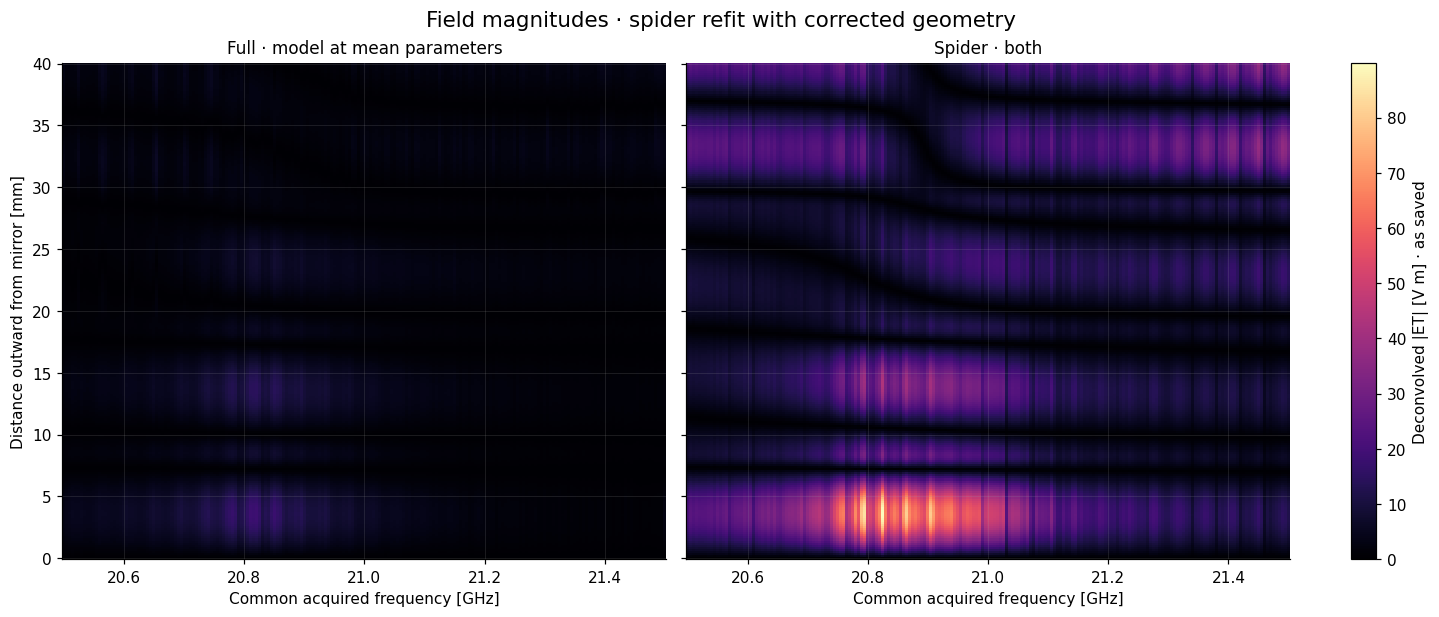

In [32]:
plots.present(
    comparison.plot_field_map_comparison(
        data, full_bead, GEOMETRY,
        title="Field magnitudes · spider refit with corrected geometry",
        x_label="Common acquired frequency [GHz]",
        y_label="Distance outward from mirror [mm]",
        colorbar_label="Deconvolved |ET| [V m] · as saved",
        full_panel_title="Full · model at mean parameters",
        spider_panel_title_template="Spider · {geometry}",
    ),
    '27_field_map_comparison', COMPARISON_DIR,
)

### Fit quality

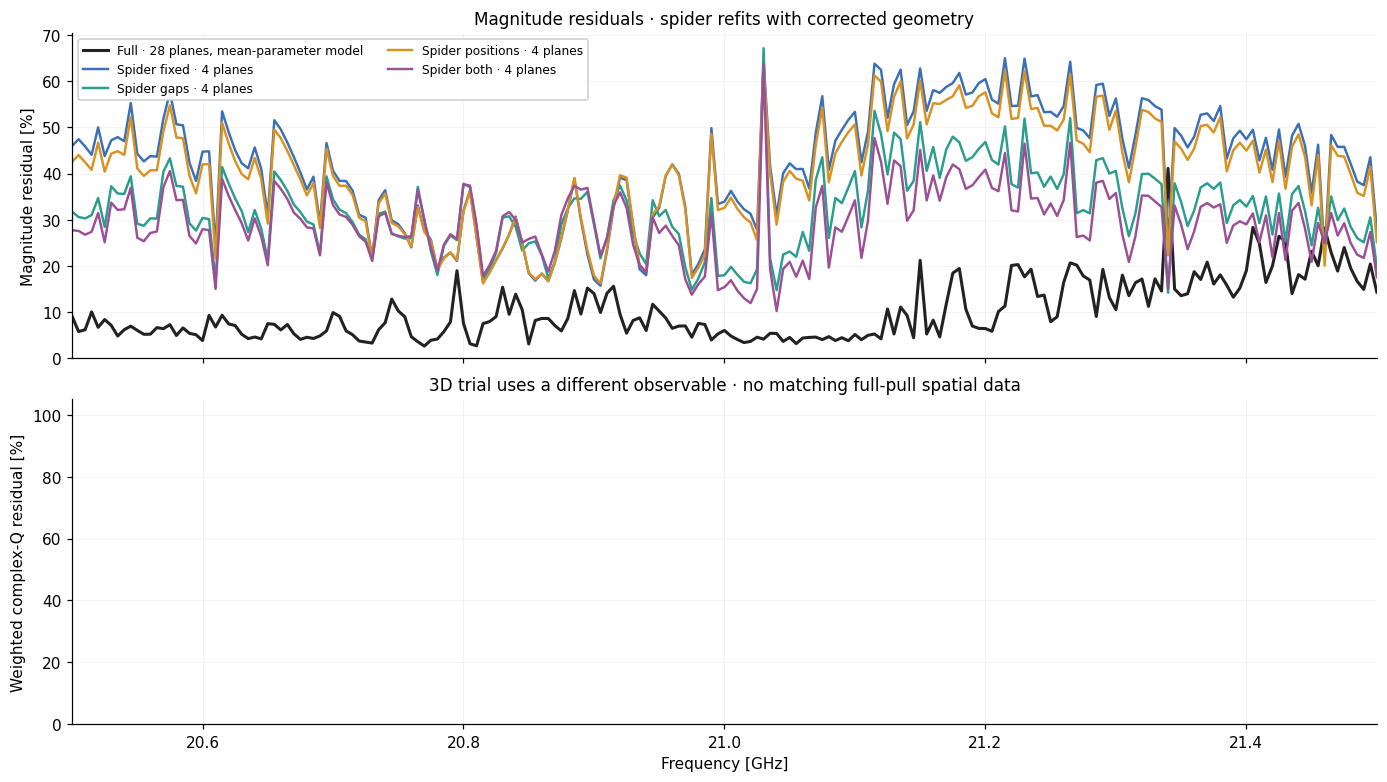

In [33]:
plots.present(
    comparison.plot_fit_quality_comparison(
        data, full_bead,
        title="Magnitude residuals · spider refits with corrected geometry",
        trial_title="3D trial uses a different observable · no matching full-pull spatial data",
        x_label="Frequency [GHz]",
        y_label="Magnitude residual [%]",
        trial_y_label="Weighted complex-Q residual [%]",
        full_curve_label_template="Full · {n_full} planes, mean-parameter model",
        spider_curve_label_template="Spider {mode} · {n_spider} planes",
        trial_curve_label="Spider 3D trial · saved frequencies",
    ),
    '29_fit_quality_comparison', COMPARISON_DIR,
)

## Interactive explorer

Optional; requires a running kernel and widget support.

In [34]:
SHOW_INTERACTIVE = False
if SHOW_INTERACTIVE:
    plots.interactive_explorer(
        data, FREQUENCY_GHZ, GEOMETRY,
        plot_functions={
            "diagnostic": diagnostic_plot,
            "radial": radial_fields_plot,
            "reference": reference_subtraction_plot,
            "center": beam_center_plot,
            "transverse": transverse_maps_plot,
        },
        frequency_control_label="GHz",
        geometry_control_label="1D case",
        view_control_label="View",
        diagnostic_view_label="1D field + setup",
        radial_view_label="Radial field",
        reference_view_label="Reference subtraction",
        center_view_label="Beam-centre symmetry",
        transverse_view_label="Transverse reconstruction",
        spatial_view_label="3D saved profiles",
        fixed_geometry_label="fixed",
        gaps_geometry_label="gaps",
        positions_geometry_label="positions",
        both_geometry_label="both",
    )
